# MentalDistress Phase 12: Ten-Seed Efficiency Benchmarking

This notebook measures the computational cost of the frozen MentalRoBERTa and
CTPR systems across all ten principal seeds. It performs inference benchmarking
only. It does not train, tune, select an allocation, or access the locked test.

Systems:

- `A0_flat`: native global MentalRoBERTa inference;
- `A1_conditional`: frozen hard-pair routing with `tau=0.10`;
- `A2_always_route`: the same hard-pair allocation with `tau=1.00`.

Primary timings cover GPU model-side inference. Tokenization, disk I/O, and
host-to-device transfer occur outside the timed region. The CTPR path includes
global inference, routing operations, matched specialist execution, and final
prediction construction. The Flat path bypasses all CTPR work.

Reserve roughly two hours on a Kaggle Tesla T4 for the full ten-seed run. Keep
the executed notebook because its visible progress and outputs are part of the
audit record.


In [1]:
from pathlib import Path
import gc
import hashlib
import json
import math
import os
import platform
import random
import shutil
import subprocess
import sys
import time
import warnings
import zipfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from safetensors.torch import load_file
from transformers import AutoModelForSequenceClassification, AutoTokenizer

warnings.filterwarnings("ignore", category=FutureWarning)
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

RUN_MODE = "full"
DEVICE = torch.device("cuda:0")
assert torch.cuda.is_available(), "Phase 12 requires a CUDA GPU"

ALL_SEEDS = [13, 42, 77, 123, 211, 340, 512, 1024, 2026, 3407]
SYSTEMS = ["A0_flat", "A1_conditional", "A2_always_route"]
LABELS = ["Suicidal", "Depressed", "Anxious", "Frustrated", "Others"]
LABEL_TO_ID = {label: index for index, label in enumerate(LABELS)}
ID_TO_LABEL = {index: label for label, index in LABEL_TO_ID.items()}
HARD_PAIRS = [
    "Frustrated|Others",
    "Suicidal|Depressed",
    "Depressed|Others",
]
K_FIXED = 3
PRIMARY_TAU = 0.10
ALWAYS_ROUTE_TAU = 1.00
TAU_GRID = [0.0, 0.05, 0.10, 0.20, 0.30, 0.40, 0.50, 0.70, 0.90, 1.00]
MAX_LENGTH = 512

BATCH1_EXAMPLES = 256
BATCH1_WARMUP_PER_SYSTEM = 20
BATCH1_INTERLEAVED_ROUNDS = 30
THROUGHPUT_BATCH_SIZE = 16
THROUGHPUT_REPETITIONS = 30
THROUGHPUT_WARMUP_PER_SYSTEM = 10
VRAM_BATCH_SIZE = 16
TIMING_ORDER_SEED = 2026
BENCHMARK_COHORT_SEED = 2027
BOOTSTRAP_SEED = 2028
BOOTSTRAP_REPS = 5000

EXPECTED_VALIDATION_ROWS = 1490
EXPECTED_BATCH1_RAW_ROWS = 230400
EXPECTED_THROUGHPUT_RAW_ROWS = 900
EXPECTED_VRAM_ROWS = 30
VALIDATION_SHA256 = "88835cd714b02efbd230536c7de3f455e807051a23a1786640b0e8b26b430165"
PHASE8_ZIP_SHA256 = "6d30115f9da6a1963b2fc74eb1b4c057ecb685ca7ae6dcf0c61d177bb3fa89e1"
PHASE9_ZIP_SHA256 = "9db43d16d0acd7c0fb68129ee2c2e72b88ed3a4ff73c8df7a7ecfd80fcc68ba3"
PHASE10_ZIP_SHA256 = "7d9e0065632e024d4f9aece380a72cefec2b2bc3e03e18bf51e076229a421ff3"

INPUT_ROOT = Path("/kaggle/input")
WORKING_ROOT = Path("/kaggle/working")
OUTPUT_DIR = WORKING_ROOT / "phase12_efficiency_benchmarking_results"
FIGURE_DIR = OUTPUT_DIR / "figures"
CACHE_ROOT = WORKING_ROOT / "phase12_input_cache"
for directory in (OUTPUT_DIR, CACHE_ROOT):
    if directory.exists():
        shutil.rmtree(directory)
FIGURE_DIR.mkdir(parents=True)
CACHE_ROOT.mkdir(parents=True)
ACCESSED_INPUTS = []

assert RUN_MODE == "full"
assert len(ALL_SEEDS) == 10 and len(HARD_PAIRS) == K_FIXED
assert PRIMARY_TAU == 0.10 and ALWAYS_ROUTE_TAU == 1.00
assert EXPECTED_BATCH1_RAW_ROWS == (
    len(ALL_SEEDS)
    * BATCH1_INTERLEAVED_ROUNDS
    * BATCH1_EXAMPLES
    * len(SYSTEMS)
)
assert EXPECTED_THROUGHPUT_RAW_ROWS == (
    len(ALL_SEEDS) * THROUGHPUT_REPETITIONS * len(SYSTEMS)
)
assert EXPECTED_VRAM_ROWS == len(ALL_SEEDS) * len(SYSTEMS)

random.seed(TIMING_ORDER_SEED)
np.random.seed(TIMING_ORDER_SEED)
torch.manual_seed(TIMING_ORDER_SEED)
torch.cuda.manual_seed_all(TIMING_ORDER_SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)

print("CUDA device:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Seeds:", ALL_SEEDS)
print("Frozen H:", HARD_PAIRS)
print("Frozen K:", K_FIXED, "Frozen tau:", PRIMARY_TAU)
print("Expected latency rows:", EXPECTED_BATCH1_RAW_ROWS)
print("Expected throughput rows:", EXPECTED_THROUGHPUT_RAW_ROWS)
print("Expected VRAM workers:", EXPECTED_VRAM_ROWS)


CUDA device: Tesla T4
PyTorch: 2.10.0+cu128
Seeds: [13, 42, 77, 123, 211, 340, 512, 1024, 2026, 3407]
Frozen H: ['Frustrated|Others', 'Suicidal|Depressed', 'Depressed|Others']
Frozen K: 3 Frozen tau: 0.1
Expected latency rows: 230400
Expected throughput rows: 900
Expected VRAM workers: 30


## Required Kaggle inputs

Attach the locked validation dataset, the ten global model runs and summary, and
the Phase 8, Phase 9, and Phase 10 result datasets. The notebook accepts either
extracted result directories or the canonical ZIP files. It discovers inputs
recursively, verifies manifests and hashes, and rejects train, combined, or test
files before opening them. Phase 11 outputs are not required.


In [2]:
def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def reject_forbidden_input(path):
    name = Path(path).name.lower()
    if any(marker in name for marker in ("_test", "combined", "train_locked")):
        raise ValueError(f"Forbidden Phase 12 input selected: {path}")


def record_input(path, role, **extra):
    path = Path(path)
    reject_forbidden_input(path)
    row = {
        "access_order": len(ACCESSED_INPUTS) + 1,
        "role": role,
        "path": str(path),
        "sha256": sha256_file(path),
        "bytes": path.stat().st_size,
    }
    row.update(extra)
    ACCESSED_INPUTS.append(row)


def safe_extract(archive_path, destination):
    destination = Path(destination).resolve()
    with zipfile.ZipFile(archive_path) as archive:
        names = archive.namelist()
        if len(names) != len(set(names)):
            raise ValueError(f"Duplicate ZIP member: {archive_path}")
        for member_name in names:
            validate_zip_member(member_name)
            resolved = (destination / member_name).resolve()
            if not str(resolved).startswith(str(destination) + os.sep):
                raise ValueError(f"Unsafe ZIP member: {member_name}")
        archive.extractall(destination)


def verify_manifest(root):
    root = Path(root)
    manifest_path = root / "sha256_manifest.csv"
    frame = pd.read_csv(manifest_path)
    actual = {
        path.relative_to(root).as_posix()
        for path in root.rglob("*")
        if path.is_file() and path != manifest_path
    }
    if set(frame["path"]) != actual or len(frame) != len(actual):
        raise ValueError(f"Manifest membership mismatch: {root}")
    for row in frame.itertuples(index=False):
        file_path = root / row.path
        if file_path.stat().st_size != int(row.bytes):
            raise ValueError(f"Manifest byte mismatch: {row.path}")
        if sha256_file(file_path) != row.sha256:
            raise ValueError(f"Manifest hash mismatch: {row.path}")
    return frame


def choose_equivalent(paths, hash_function, description):
    paths = sorted(set(map(Path, paths)), key=str)
    if not paths:
        raise FileNotFoundError(description)
    hashes = {hash_function(path) for path in paths}
    if len(hashes) != 1:
        raise ValueError(f"Conflicting candidates for {description}: {paths}")
    return paths[0]


def find_input(filename, role, expected_sha256=None):
    candidates = sorted(INPUT_ROOT.rglob(filename), key=str)
    if not candidates:
        raise FileNotFoundError(filename)
    if expected_sha256 is not None:
        observed_hashes = {sha256_file(path) for path in candidates}
        if observed_hashes != {expected_sha256}:
            raise ValueError(
                f"Conflicting SHA-256 candidates for {filename}: "
                f"{sorted(observed_hashes)}"
            )
    path = choose_equivalent(candidates, sha256_file, filename)
    reject_forbidden_input(path)
    record_input(
        path,
        role,
        discovery_method="recursive_file",
        expected_sha256=expected_sha256 or "not_frozen",
    )
    return path


def resolve_result_dir(directory_name, archive_name, expected_archive_sha256):
    directories = [
        path for path in INPUT_ROOT.rglob(directory_name) if path.is_dir()
    ]
    archives = sorted(INPUT_ROOT.rglob(archive_name), key=str)
    archive_path = None
    if archives:
        observed_hashes = {sha256_file(path) for path in archives}
        if observed_hashes != {expected_archive_sha256}:
            raise ValueError(
                f"Conflicting SHA-256 candidates for {archive_name}: "
                f"{sorted(observed_hashes)}"
            )
        archive_path = choose_equivalent(archives, sha256_file, archive_name)
        record_input(
            archive_path,
            directory_name + "_archive",
            discovery_method="recursive_archive",
            expected_sha256=expected_archive_sha256,
        )
    if directories:
        root = choose_equivalent(
            directories,
            lambda path: sha256_file(path / "sha256_manifest.csv"),
            directory_name,
        )
        discovery_method = "extracted_directory"
    else:
        if archive_path is None:
            raise FileNotFoundError(
                f"Missing extracted directory or archive: {directory_name}"
            )
        cache = CACHE_ROOT / directory_name
        cache.mkdir(parents=True)
        safe_extract(archive_path, cache)
        root = cache / directory_name
        discovery_method = "verified_archive_extraction"
    verify_manifest(root)
    record_input(
        root / "sha256_manifest.csv",
        directory_name + "_manifest",
        discovery_method=discovery_method,
        manifest_status="PASS",
    )
    return root


def discover_phase_inputs():
    return {
        "validation": find_input(
            "MentalDistress_validation_LOCKED.csv",
            "locked_validation",
            VALIDATION_SHA256,
        ),
        "summary": find_input(
            "mentalroberta_full_10seed_summary.csv",
            "global_summary",
        ),
        "phase8": resolve_result_dir(
            "phase8_all_pair_specialists_results",
            "MentalDistress_Phase8_All_Pair_Specialists_Results.zip",
            PHASE8_ZIP_SHA256,
        ),
        "phase9": resolve_result_dir(
            "phase9_routing_calibration_results",
            "MentalDistress_Phase9_Routing_Calibration_Results.zip",
            PHASE9_ZIP_SHA256,
        ),
        "phase10": resolve_result_dir(
            "phase10_controls_allocation_results",
            "MentalDistress_Phase10_Controls_and_Allocation_Results.zip",
            PHASE10_ZIP_SHA256,
        ),
    }


def write_json(path, payload):
    Path(path).write_text(
        json.dumps(payload, indent=2, sort_keys=True) + "\n",
        encoding="utf-8",
    )


def pair_slug(pair_name):
    first, second = pair_name.split("|")
    return first.lower() + "__" + second.lower()


print("PASS: path-safe Phase 12 input helpers initialized")


PASS: path-safe Phase 12 input helpers initialized


## Lightweight deterministic self-tests

These checks exercise archive safety, canonical pairs, deterministic disjoint
cohorts, parameter and MAC formulas, bootstrap repeatability, interleaved timing
structure, and deterministic ZIP construction before any model outcome is used.


In [3]:
import hashlib
import zipfile
from pathlib import Path
from pathlib import PurePosixPath

import numpy as np


FIXED_ZIP_TIME = (2020, 1, 1, 0, 0, 0)


def canonical_pair(first, second, labels):
    labels = tuple(labels)
    if first == second:
        raise ValueError("A pair requires two distinct labels")
    if first not in labels or second not in labels:
        raise ValueError("Pair contains an unknown label")
    ordered = sorted((first, second), key=labels.index)
    return "|".join(ordered)


def validate_zip_member(member):
    path = PurePosixPath(str(member))
    if path.is_absolute() or not path.parts or ".." in path.parts:
        raise ValueError(f"Unsafe ZIP member: {member}")
    normalized = path.as_posix()
    if normalized in {"", "."}:
        raise ValueError(f"Unsafe ZIP member: {member}")
    return normalized


def select_disjoint_cohorts(total_rows, latency_rows, throughput_rows, seed):
    total_rows = int(total_rows)
    latency_rows = int(latency_rows)
    throughput_rows = int(throughput_rows)
    if min(total_rows, latency_rows, throughput_rows) < 0:
        raise ValueError("Cohort sizes must be nonnegative")
    if latency_rows + throughput_rows > total_rows:
        raise ValueError("Requested cohorts exceed the available rows")
    permutation = np.random.default_rng(int(seed)).permutation(total_rows)
    latency = permutation[:latency_rows].astype(int, copy=True)
    throughput = permutation[
        latency_rows : latency_rows + throughput_rows
    ].astype(int, copy=True)
    return latency, throughput


def specialist_parameter_accounting(hidden_size, head_count):
    hidden_size = int(hidden_size)
    head_count = int(head_count)
    if hidden_size <= 0 or head_count < 0:
        raise ValueError("Invalid specialist dimensions")
    per_head = hidden_size * 2 + 2
    return {
        "parameters_per_head": per_head,
        "added_parameters": per_head * head_count,
    }


def specialist_compute_accounting(routed_count, row_count, hidden_size=768):
    routed_count = int(routed_count)
    row_count = int(row_count)
    hidden_size = int(hidden_size)
    if row_count <= 0 or routed_count < 0 or routed_count > row_count:
        raise ValueError("Invalid routed or row count")
    if hidden_size <= 0:
        raise ValueError("hidden_size must be positive")
    per_route = hidden_size * 2
    coverage = routed_count / row_count
    return {
        "routed_count": routed_count,
        "routing_coverage": float(coverage),
        "macs_per_route": per_route,
        "coverage_weighted_macs": float(coverage * per_route),
        "total_added_macs": routed_count * per_route,
    }


def _statistic_function(statistic):
    if statistic == "mean":
        return np.mean
    if statistic == "median":
        return np.median
    if callable(statistic):
        return statistic
    raise ValueError(f"Unsupported bootstrap statistic: {statistic}")


def bootstrap_ci(values, statistic="mean", reps=5000, seed=2028, alpha=0.05):
    values = np.asarray(values, dtype=float)
    if values.ndim != 1 or len(values) == 0 or not np.isfinite(values).all():
        raise ValueError("Bootstrap values must be one finite nonempty vector")
    reps = int(reps)
    if reps <= 0 or not 0.0 < float(alpha) < 1.0:
        raise ValueError("Invalid bootstrap configuration")
    rng = np.random.default_rng(int(seed))
    indices = rng.integers(0, len(values), size=(reps, len(values)))
    sampled = values[indices]
    function = _statistic_function(statistic)
    estimates = function(sampled, axis=1)
    lower, upper = np.quantile(
        estimates,
        [float(alpha) / 2.0, 1.0 - float(alpha) / 2.0],
    )
    return float(lower), float(upper)


def paired_change_ci(system_values, flat_values, reps=5000, seed=2028):
    system_values = np.asarray(system_values, dtype=float)
    flat_values = np.asarray(flat_values, dtype=float)
    if system_values.shape != flat_values.shape or system_values.ndim != 1:
        raise ValueError("Paired vectors must have the same one-dimensional shape")
    differences = system_values - flat_values
    lower, upper = bootstrap_ci(
        differences,
        statistic="mean",
        reps=reps,
        seed=seed,
    )
    return {
        "mean_change": float(np.mean(differences)),
        "ci_low": lower,
        "ci_high": upper,
    }


def latency_overhead_percent(system_latency, flat_latency):
    system_latency = float(system_latency)
    flat_latency = float(flat_latency)
    if not np.isfinite(system_latency) or not np.isfinite(flat_latency):
        raise ValueError("Latency values must be finite")
    if flat_latency <= 0.0:
        raise ValueError("Flat latency must be positive")
    return float(100.0 * (system_latency - flat_latency) / flat_latency)


def validate_interleaved_structure(
    rows,
    key_fields,
    unit_fields,
    systems,
):
    rows = list(rows)
    key_fields = tuple(key_fields)
    unit_fields = tuple(unit_fields)
    systems = tuple(systems)
    keys = [tuple(row[field] for field in key_fields) for row in rows]
    if len(keys) != len(set(keys)):
        raise ValueError("Duplicate interleaved timing key")
    grouped = {}
    for row in rows:
        unit = tuple(row[field] for field in unit_fields)
        grouped.setdefault(unit, []).append(row)
    expected = set(systems)
    for unit, unit_rows in grouped.items():
        observed = {row["system_id"] for row in unit_rows}
        if observed != expected or len(unit_rows) != len(systems):
            raise ValueError(f"Incomplete interleaved unit: {unit}")
        positions = {int(row["order_position"]) for row in unit_rows}
        if positions != set(range(len(systems))):
            raise ValueError(f"Invalid order positions for unit: {unit}")
    return {
        "passed": True,
        "row_count": len(rows),
        "unit_count": len(grouped),
        "system_count": len(systems),
    }


def deterministic_zip(source_dir, zip_path, archive_root):
    source_dir = Path(source_dir)
    zip_path = Path(zip_path)
    if not source_dir.is_dir():
        raise ValueError(f"Missing ZIP source directory: {source_dir}")
    archive_root = validate_zip_member(archive_root)
    with zipfile.ZipFile(
        zip_path,
        mode="w",
        compression=zipfile.ZIP_DEFLATED,
        compresslevel=9,
    ) as archive:
        for source_path in sorted(
            path for path in source_dir.rglob("*") if path.is_file()
        ):
            relative = source_path.relative_to(source_dir).as_posix()
            archive_name = validate_zip_member(f"{archive_root}/{relative}")
            info = zipfile.ZipInfo(archive_name, date_time=FIXED_ZIP_TIME)
            info.compress_type = zipfile.ZIP_DEFLATED
            info.external_attr = 0o600 << 16
            archive.writestr(info, source_path.read_bytes())
    return hashlib.sha256(zip_path.read_bytes()).hexdigest()


## Input integrity

This section verifies the 1,490-row locked validation split, all 100 Phase 8 heads,
the frozen Phase 9 router, the audited Phase 10 record, and every canonical global
model manifest. Any mismatch stops execution before benchmarking.


In [4]:
assert canonical_pair("Others", "Frustrated", LABELS) == "Frustrated|Others"
latency_test, throughput_test = select_disjoint_cohorts(
    1490, 256, 480, BENCHMARK_COHORT_SEED
)
assert set(latency_test).isdisjoint(set(throughput_test))
assert specialist_parameter_accounting(768, 3)["added_parameters"] == 4614
assert specialist_compute_accounting(10, 100)["total_added_macs"] == 15360
assert bootstrap_ci([1, 2, 3], reps=1000, seed=7) == bootstrap_ci(
    [1, 2, 3], reps=1000, seed=7
)

helper_dir = WORKING_ROOT / "phase12_helper_test"
helper_dir.mkdir()
(helper_dir / "payload.txt").write_text("phase12\n", encoding="utf-8")
helper_zip_one = WORKING_ROOT / "phase12_helper_one.zip"
helper_zip_two = WORKING_ROOT / "phase12_helper_two.zip"
helper_hash_one = deterministic_zip(helper_dir, helper_zip_one, "results")
helper_hash_two = deterministic_zip(helper_dir, helper_zip_two, "results")
assert helper_hash_one == helper_hash_two
with zipfile.ZipFile(helper_zip_one) as helper_archive:
    assert all(
        info.date_time == (2020, 1, 1, 0, 0, 0)
        for info in helper_archive.infolist()
    )
shutil.rmtree(helper_dir)
helper_zip_one.unlink()
helper_zip_two.unlink()
print("PASS: lightweight Phase 12 helper tests")

discovered = discover_phase_inputs()
VALIDATION_PATH = discovered["validation"]
SUMMARY_PATH = discovered["summary"]
PHASE8_ROOT = discovered["phase8"]
PHASE9_ROOT = discovered["phase9"]
PHASE10_ROOT = discovered["phase10"]

validation = pd.read_csv(VALIDATION_PATH)
assert len(validation) == EXPECTED_VALIDATION_ROWS
assert {"original_row", "text", "label"}.issubset(validation.columns)
assert validation["original_row"].is_unique
assert set(validation["label"]) == set(LABELS)
y_validation = validation["label"].map(LABEL_TO_ID).to_numpy(dtype=int)

phase8_protocol_path = PHASE8_ROOT / "phase8_protocol.json"
record_input(phase8_protocol_path, "phase8_protocol")
phase8_protocol = json.loads(phase8_protocol_path.read_text(encoding="utf-8"))
assert phase8_protocol["phase"] == 8
assert phase8_protocol["head_count"] == 100
assert phase8_protocol["model_seeds"] == ALL_SEEDS
assert phase8_protocol["phase5_frozen_H"] == HARD_PAIRS
assert phase8_protocol["phase5_frozen_K"] == K_FIXED
assert phase8_protocol["head_architecture"] == "Linear(hidden_size, 2)"
assert phase8_protocol["encoder_frozen"] is True
assert phase8_protocol["representation"] == "final_hidden_state_token_0"
assert phase8_protocol["float_policy"] == "float32 encoder inference and head training"
assert phase8_protocol["labels"] == LABELS
assert phase8_protocol["test_accessed"] is False

verified_head_count = 0
verified_selected_head_count = 0
for model_seed in ALL_SEEDS:
    for pair_name in phase8_protocol["pairs"]:
        head_dir = (
            PHASE8_ROOT / "heads" / f"seed_{model_seed}" / pair_slug(pair_name)
        )
        metadata = json.loads((head_dir / "metadata.json").read_text())
        head_path = head_dir / "head.safetensors"
        record_input(
            head_dir / "metadata.json",
            "phase8_head_metadata",
            model_seed=model_seed,
            pair=pair_name,
        )
        record_input(
            head_path,
            "phase8_head_weights",
            model_seed=model_seed,
            pair=pair_name,
        )
        assert metadata["model_seed"] == model_seed
        assert metadata["pair"] == pair_name
        assert metadata["architecture"] == "Linear(hidden_size, 2)"
        assert metadata["hidden_size"] == 768
        assert metadata["encoder_frozen"] is True
        assert metadata["representation"] == "final_hidden_state_token_0"
        assert metadata["validation_sha256"] == VALIDATION_SHA256
        assert metadata["test_accessed"] is False
        assert sha256_file(head_path) == metadata["head_sha256"]
        verified_head_count += 1
        if pair_name in HARD_PAIRS:
            verified_selected_head_count += 1
assert verified_head_count == 100
assert verified_selected_head_count == 30

phase9_config_path = PHASE9_ROOT / "phase9_selected_config.json"
record_input(phase9_config_path, "phase9_selected_config")
phase9_config = json.loads(phase9_config_path.read_text(encoding="utf-8"))
assert phase9_config["phase"] == 9
assert phase9_config["K_fixed"] == K_FIXED
assert phase9_config["H"] == HARD_PAIRS
assert phase9_config["tau_grid"] == TAU_GRID
assert np.isclose(phase9_config["selected_tau"], PRIMARY_TAU)
assert phase9_config["selected_mode"] == "specialist_routing"
assert phase9_config["test_accessed"] is False

phase10_protocol_path = PHASE10_ROOT / "phase10_protocol.json"
phase10_execution_path = PHASE10_ROOT / "phase10_execution_summary.json"
record_input(phase10_protocol_path, "phase10_protocol")
record_input(phase10_execution_path, "phase10_execution_summary")
phase10_protocol = json.loads(
    phase10_protocol_path.read_text(encoding="utf-8")
)
phase10_execution = json.loads(
    phase10_execution_path.read_text(encoding="utf-8")
)
assert phase10_protocol["phase"] == 10
assert phase10_protocol["model_seeds"] == ALL_SEEDS
assert phase10_protocol["labels"] == LABELS
assert phase10_protocol["H"] == HARD_PAIRS
assert phase10_protocol["K"] == K_FIXED
assert phase10_protocol["tau_grid"] == TAU_GRID
assert np.isclose(phase10_protocol["frozen_tau"], PRIMARY_TAU)
assert phase10_protocol["test_accessed"] is False
assert phase10_execution["status"] == "PASS"
assert phase10_execution["phase9_reproduction_pass_count"] == 10
assert phase10_execution["test_accessed"] is False

global_summary = pd.read_csv(SUMMARY_PATH)
assert sorted(global_summary["seed"].astype(int).tolist()) == ALL_SEEDS
MODEL_DIRS = {}
GLOBAL_RUNS = {}
for summary_row in global_summary.itertuples(index=False):
    model_seed = int(summary_row.seed)
    candidates = [
        path
        for path in INPUT_ROOT.rglob(str(summary_row.run_id))
        if path.is_dir()
        and (path / "models/best_model/model.safetensors").is_file()
        and (path / "artifacts/validation_predictions.csv").is_file()
    ]
    run_dir = choose_equivalent(
        candidates,
        lambda path: sha256_file(path / "models/sha256_manifest.csv"),
        str(summary_row.run_id),
    )
    verify_manifest(run_dir / "models")
    verify_manifest(run_dir / "artifacts")
    MODEL_DIRS[model_seed] = run_dir / "models/best_model"
    GLOBAL_RUNS[model_seed] = run_dir
    record_input(
        run_dir / "models/sha256_manifest.csv",
        "global_model_manifest",
        model_seed=model_seed,
    )
    record_input(
        run_dir / "artifacts/sha256_manifest.csv",
        "global_artifact_manifest",
        model_seed=model_seed,
    )
assert sorted(MODEL_DIRS) == ALL_SEEDS
print("Validation rows:", len(validation))
print("Verified Phase 8 heads:", verified_head_count)
print("Verified selected Phase 8 heads:", verified_selected_head_count)
print("PASS: Phase 8, Phase 9, Phase 10, and ten checkpoints verified")


PASS: lightweight Phase 12 helper tests
Validation rows: 1490
Verified Phase 8 heads: 100
Verified selected Phase 8 heads: 30
PASS: Phase 8, Phase 9, Phase 10, and ten checkpoints verified


## Frozen model and specialist forward paths

Each seed loads its global model and the three selected Phase 8 heads. Metadata
controls local-to-global label mapping. A0 exits after global argmax. A1 and A2
apply at most one matched head to each routed row.


In [5]:
class PairHead(nn.Module):
    def __init__(self, hidden_size=768):
        super().__init__()
        self.classifier = nn.Linear(hidden_size, 2)

    def forward(self, features):
        return self.classifier(features)


def load_selected_heads(model_seed, device=DEVICE):
    weights = []
    biases = []
    class_maps = []
    metadata_rows = []
    for pair_name in HARD_PAIRS:
        head_dir = (
            PHASE8_ROOT
            / "heads"
            / f"seed_{model_seed}"
            / pair_slug(pair_name)
        )
        metadata = json.loads((head_dir / "metadata.json").read_text())
        head_path = head_dir / "head.safetensors"
        assert metadata["pair"] == pair_name
        assert metadata["model_seed"] == model_seed
        assert metadata["class_mapping"] == {
            metadata["class_a"]: 0,
            metadata["class_b"]: 1,
        }
        assert sha256_file(head_path) == metadata["head_sha256"]
        state = load_file(str(head_path), device="cpu")
        assert set(state) == {"classifier.weight", "classifier.bias"}
        assert tuple(state["classifier.weight"].shape) == (2, 768)
        weights.append(state["classifier.weight"].float())
        biases.append(state["classifier.bias"].float())
        class_maps.append(
            [
                LABEL_TO_ID[metadata["class_a"]],
                LABEL_TO_ID[metadata["class_b"]],
            ]
        )
        metadata_rows.append(metadata)
    pair_lookup = torch.full((len(LABELS), len(LABELS)), -1, dtype=torch.long)
    for pair_index, pair_name in enumerate(HARD_PAIRS):
        first, second = pair_name.split("|")
        first_id = LABEL_TO_ID[first]
        second_id = LABEL_TO_ID[second]
        pair_lookup[first_id, second_id] = pair_index
        pair_lookup[second_id, first_id] = pair_index
    return {
        "weights": torch.stack(weights).to(device),
        "biases": torch.stack(biases).to(device),
        "class_maps": torch.tensor(class_maps, dtype=torch.long, device=device),
        "pair_lookup": pair_lookup.to(device),
        "pair_names": tuple(HARD_PAIRS),
        "metadata": metadata_rows,
    }


def forward_system(model, head_bundle, batch, system_id, return_details=False):
    with torch.inference_mode(), torch.autocast(
        device_type="cuda", enabled=False
    ):
        encoded = model.roberta(**batch, return_dict=True)
        sequence = encoded.last_hidden_state
        logits = model.classifier(sequence)
        global_prediction = torch.argmax(logits, dim=1)
        if system_id == "A0_flat":
            if return_details:
                return {
                    "prediction": global_prediction,
                    "global_prediction": global_prediction,
                }
            return global_prediction
        if system_id == "A1_conditional":
            tau = PRIMARY_TAU
        elif system_id == "A2_always_route":
            tau = ALWAYS_ROUTE_TAU
        else:
            raise KeyError(system_id)
        probabilities = torch.softmax(logits, dim=1)
        top_values, top_ids = torch.topk(probabilities, k=2, dim=1)
        margin = top_values[:, 0] - top_values[:, 1]
        pair_index = head_bundle["pair_lookup"][top_ids[:, 0], top_ids[:, 1]]
        active = (pair_index >= 0) & (margin <= tau)
        final_prediction = top_ids[:, 0].clone()
        active_count = int(active.sum().item())
        if active_count:
            selected = pair_index[active]
            selected_weights = head_bundle["weights"][selected]
            selected_biases = head_bundle["biases"][selected]
            features = sequence[active, 0, :].unsqueeze(2)
            pair_logits = torch.bmm(selected_weights, features).squeeze(2)
            pair_logits = pair_logits + selected_biases
            local_prediction = torch.argmax(pair_logits, dim=1)
            global_pair_prediction = head_bundle["class_maps"][
                selected, local_prediction
            ]
            final_prediction[active] = global_pair_prediction
        if not return_details:
            return final_prediction
        return {
            "prediction": final_prediction,
            "global_prediction": global_prediction,
            "probabilities": probabilities,
            "top2": top_ids,
            "margin": margin,
            "active": active,
            "pair_index": pair_index,
        }


def to_gpu_batch(tokenizer, texts):
    encoded = tokenizer(
        list(texts),
        padding=True,
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    )
    return {name: tensor.to(DEVICE) for name, tensor in encoded.items()}


def classification_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    f1_values = []
    recalls = []
    for class_id in range(len(LABELS)):
        true_positive = int(np.sum((y_true == class_id) & (y_pred == class_id)))
        false_positive = int(np.sum((y_true != class_id) & (y_pred == class_id)))
        false_negative = int(np.sum((y_true == class_id) & (y_pred != class_id)))
        support = int(np.sum(y_true == class_id))
        denominator = 2 * true_positive + false_positive + false_negative
        f1_values.append(2 * true_positive / denominator if denominator else 0.0)
        recalls.append(true_positive / support if support else 0.0)
    return {
        "accuracy": float(np.mean(y_true == y_pred)),
        "macro_f1": float(np.mean(f1_values)),
        "balanced_accuracy": float(np.mean(recalls)),
    }


class _ToyEncoder:
    def __init__(self, sequence):
        self.sequence = sequence

    def __call__(self, **unused):
        return type("ToyOutput", (), {"last_hidden_state": self.sequence})()


class _ToyClassifier:
    def __init__(self, logits):
        self.logits = logits

    def __call__(self, unused_sequence):
        return self.logits


class _ToyModel:
    def __init__(self, sequence, logits):
        self.roberta = _ToyEncoder(sequence)
        self.classifier = _ToyClassifier(logits)


toy_sequence = torch.zeros((1, 2, 768), dtype=torch.float32, device=DEVICE)
toy_pair_lookup = torch.full((5, 5), -1, dtype=torch.long, device=DEVICE)
toy_pair_lookup[0, 1] = toy_pair_lookup[1, 0] = 0
toy_heads = {
    "weights": torch.zeros((1, 2, 768), dtype=torch.float32, device=DEVICE),
    "biases": torch.tensor([[0.0, 1.0]], dtype=torch.float32, device=DEVICE),
    "class_maps": torch.tensor([[0, 1]], dtype=torch.long, device=DEVICE),
    "pair_lookup": toy_pair_lookup,
}
toy_batch = {"input_ids": torch.zeros((1, 2), dtype=torch.long, device=DEVICE)}
toy_model = _ToyModel(
    toy_sequence,
    torch.tensor([[5.0, 0.0, -5.0, -5.0, -5.0]], device=DEVICE),
)
toy_flat = forward_system(toy_model, None, toy_batch, "A0_flat")
toy_conditional = forward_system(
    toy_model, toy_heads, toy_batch, "A1_conditional", return_details=True
)
toy_always = forward_system(
    toy_model, toy_heads, toy_batch, "A2_always_route", return_details=True
)
assert toy_flat.item() == 0
assert not toy_conditional["active"].item()
assert toy_always["active"].item() and toy_always["prediction"].item() == 1
toy_model.classifier.logits = torch.tensor(
    [[0.05, 0.0, -5.0, -5.0, -5.0]], device=DEVICE
)
toy_one_route = forward_system(
    toy_model, toy_heads, toy_batch, "A1_conditional", return_details=True
)
assert toy_one_route["active"].item()
assert toy_one_route["prediction"].item() == 1
del toy_sequence, toy_pair_lookup, toy_heads, toy_batch, toy_model

print("PASS: architecture-faithful Phase 12 forward paths initialized")


PASS: architecture-faithful Phase 12 forward paths initialized


## Phase 10 reproduction gate

The exact Phase 12 forward implementation runs over all 1,490 validation rows for
every seed. A0, A1, and A2 predictions, routing masks, routed pairs, top-two IDs,
and margins must reproduce Phase 10 before any timing output is accepted.


In [6]:
def infer_full_validation(model_seed, batch_size=16):
    tokenizer = AutoTokenizer.from_pretrained(
        MODEL_DIRS[model_seed], local_files_only=True
    )
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_DIRS[model_seed],
        local_files_only=True,
        torch_dtype=torch.float32,
    ).eval().to(DEVICE)
    heads = load_selected_heads(model_seed)
    collected = {
        "A0_flat": [],
        "A1_conditional": [],
        "A2_always_route": [],
        "A1_active": [],
        "A2_active": [],
        "A1_pair_index": [],
        "A2_pair_index": [],
        "top2": [],
        "margin": [],
    }
    texts = validation["text"].astype(str).tolist()
    for start in range(0, len(texts), batch_size):
        batch = to_gpu_batch(tokenizer, texts[start : start + batch_size])
        flat = forward_system(model, heads, batch, "A0_flat")
        conditional = forward_system(
            model, heads, batch, "A1_conditional", return_details=True
        )
        always = forward_system(
            model, heads, batch, "A2_always_route", return_details=True
        )
        assert torch.equal(flat, conditional["global_prediction"])
        assert torch.equal(flat, always["global_prediction"])
        assert torch.equal(conditional["top2"], always["top2"])
        collected["A0_flat"].append(flat.cpu())
        collected["A1_conditional"].append(
            conditional["prediction"].cpu()
        )
        collected["A2_always_route"].append(always["prediction"].cpu())
        collected["A1_active"].append(conditional["active"].cpu())
        collected["A2_active"].append(always["active"].cpu())
        collected["A1_pair_index"].append(
            conditional["pair_index"].cpu()
        )
        collected["A2_pair_index"].append(always["pair_index"].cpu())
        collected["top2"].append(conditional["top2"].cpu())
        collected["margin"].append(conditional["margin"].cpu())
    output = {
        key: torch.cat(parts).numpy() for key, parts in collected.items()
    }
    del heads, model, tokenizer
    gc.collect()
    torch.cuda.empty_cache()
    return output


phase10_performance_path = PHASE10_ROOT / "phase10_control_seedwise.csv"
record_input(phase10_performance_path, "phase10_control_seedwise")
phase10_performance = pd.read_csv(phase10_performance_path)
phase10_performance = phase10_performance[
    phase10_performance["control_id"].isin(SYSTEMS)
].copy()
phase10_performance = phase10_performance.rename(
    columns={"control_id": "system_id"}
)
assert len(phase10_performance) == 30


def strict_bool_array(series):
    normalized = series.astype(str).str.strip().str.lower()
    assert set(normalized.unique()).issubset({"true", "false"})
    return normalized.eq("true").to_numpy()

reproduction_rows = []
for seed_index, model_seed in enumerate(ALL_SEEDS, start=1):
    print(f"reproduction [{seed_index}/10] seed {model_seed}")
    inferred = infer_full_validation(model_seed)
    top2 = inferred["top2"]
    margin = inferred["margin"]
    record = {
        "model_seed": model_seed,
        "A0_exact": True,
        "A1_exact": True,
        "A2_exact": True,
        "routing_exact": True,
        "pair_exact": True,
        "top2_exact": True,
        "routing_count_exact": True,
        "routing_coverage_exact": True,
        "margin_max_abs_diff": 0.0,
        "metric_max_abs_diff": 0.0,
        "status": "PASS",
    }
    margin_differences = []
    metric_differences = []
    for system_id, active_key, pair_key in (
        ("A0_flat", None, None),
        ("A1_conditional", "A1_active", "A1_pair_index"),
        ("A2_always_route", "A2_active", "A2_pair_index"),
    ):
        saved_path = (
            PHASE10_ROOT
            / "controls"
            / system_id
            / f"seed_{model_seed}"
            / "validation_predictions.csv"
        )
        record_input(
            saved_path,
            "phase10_validation_predictions",
            model_seed=model_seed,
            system_id=system_id,
        )
        saved = pd.read_csv(saved_path)
        assert np.array_equal(
            saved["original_row"].to_numpy(),
            validation["original_row"].to_numpy(),
        )
        assert np.array_equal(
            saved["final_id"].to_numpy(dtype=int),
            inferred[system_id].astype(int),
        )
        assert np.array_equal(
            saved["global_id"].to_numpy(dtype=int),
            inferred["A0_flat"].astype(int),
        )
        assert np.array_equal(saved["top1"].to_numpy(dtype=int), top2[:, 0])
        assert np.array_equal(saved["top2"].to_numpy(dtype=int), top2[:, 1])
        if active_key is None:
            inferred_active = np.zeros(len(validation), dtype=bool)
            inferred_pairs = np.full(len(validation), "", dtype=object)
        else:
            inferred_active = inferred[active_key].astype(bool)
            inferred_pairs = np.array(
                [
                    HARD_PAIRS[int(pair_index)] if is_active else ""
                    for pair_index, is_active in zip(
                        inferred[pair_key], inferred_active
                    )
                ],
                dtype=object,
            )
        assert np.array_equal(
            strict_bool_array(saved["active"]), inferred_active
        )
        assert np.array_equal(
            saved["routed_pair"].fillna("").to_numpy(), inferred_pairs
        )
        margin_difference = float(
            np.max(np.abs(saved["margin"].to_numpy(dtype=float) - margin))
        )
        assert margin_difference <= 1e-6
        margin_differences.append(margin_difference)
        calculated = classification_metrics(
            y_validation, inferred[system_id].astype(int)
        )
        saved_metric = phase10_performance[
            (phase10_performance["model_seed"] == model_seed)
            & (phase10_performance["system_id"] == system_id)
        ].iloc[0]
        calculated_routed_n = int(inferred_active.sum())
        calculated_coverage = calculated_routed_n / len(validation)
        assert calculated_routed_n == int(saved_metric["routed_n"])
        assert abs(
            calculated_coverage - float(saved_metric["routing_coverage"])
        ) <= 1e-12
        for metric_name in ("accuracy", "macro_f1", "balanced_accuracy"):
            difference = abs(
                calculated[metric_name] - float(saved_metric[metric_name])
            )
            assert difference <= 1e-12
            metric_differences.append(difference)
    record["margin_max_abs_diff"] = max(margin_differences)
    record["metric_max_abs_diff"] = max(metric_differences)
    reproduction_rows.append(record)

phase12_reproduction_seedwise = pd.DataFrame(reproduction_rows)
assert len(phase12_reproduction_seedwise) == 10
assert phase12_reproduction_seedwise["status"].eq("PASS").all()
print("PASS: all ten Phase 10 A0/A1/A2 outputs reproduced")


reproduction [1/10] seed 13


`torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

reproduction [2/10] seed 42


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

...

reproduction [9/10] seed 2026


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

reproduction [10/10] seed 3407


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

PASS: all ten Phase 10 A0/A1/A2 outputs reproduced


## Deterministic benchmark cohorts

One 256-row cohort supports batch-1 latency. A disjoint 480-row cohort forms 30
throughput batches of 16. All seeds and systems use the same row identities. Text
never appears in the saved cohort files.


In [7]:
batch1_indices, throughput_indices = select_disjoint_cohorts(
    len(validation),
    BATCH1_EXAMPLES,
    THROUGHPUT_REPETITIONS * THROUGHPUT_BATCH_SIZE,
    BENCHMARK_COHORT_SEED,
)
throughput_batch_indices = throughput_indices.reshape(
    THROUGHPUT_REPETITIONS, THROUGHPUT_BATCH_SIZE
)
assert set(batch1_indices).isdisjoint(set(throughput_indices))

phase12_batch1_cohort = pd.DataFrame(
    {
        "cohort_position": np.arange(BATCH1_EXAMPLES),
        "validation_position": batch1_indices,
        "original_row": validation.iloc[batch1_indices][
            "original_row"
        ].to_numpy(),
    }
)
throughput_cohort_rows = []
for repetition, positions in enumerate(throughput_batch_indices):
    for batch_position, validation_position in enumerate(positions):
        throughput_cohort_rows.append(
            {
                "repetition": repetition,
                "batch_position": batch_position,
                "validation_position": int(validation_position),
                "original_row": validation.iloc[int(validation_position)][
                    "original_row"
                ],
            }
        )
phase12_throughput_cohort = pd.DataFrame(throughput_cohort_rows)
assert len(phase12_throughput_cohort) == 480


def prepare_gpu_benchmarks(tokenizer):
    batch1_gpu = []
    batch1_lengths = []
    for validation_position in batch1_indices:
        text = str(validation.iloc[int(validation_position)]["text"])
        batch = to_gpu_batch(tokenizer, [text])
        batch1_gpu.append(batch)
        batch1_lengths.append(int(batch["attention_mask"].sum().item()))
    throughput_gpu = []
    throughput_max_lengths = []
    throughput_mean_lengths = []
    for positions in throughput_batch_indices:
        texts = validation.iloc[positions]["text"].astype(str).tolist()
        batch = to_gpu_batch(tokenizer, texts)
        lengths = batch["attention_mask"].sum(dim=1).cpu().numpy()
        throughput_gpu.append(batch)
        throughput_max_lengths.append(int(lengths.max()))
        throughput_mean_lengths.append(float(lengths.mean()))
    return {
        "batch1_gpu": batch1_gpu,
        "batch1_lengths": batch1_lengths,
        "throughput_gpu": throughput_gpu,
        "throughput_max_lengths": throughput_max_lengths,
        "throughput_mean_lengths": throughput_mean_lengths,
    }


print("PASS: deterministic disjoint timing cohorts frozen")


PASS: deterministic disjoint timing cohorts frozen


## Batch-1 latency

Each seed receives 20 warm-up calls per system. Measurement then uses 30 rounds of
256 examples. System order is shuffled for every example and CUDA synchronization
brackets each model-side timing observation.


In [8]:
def benchmark_batch1_latency(model_seed, model, heads, benchmark):
    rows = []
    for system_id in SYSTEMS:
        for warmup_index in range(BATCH1_WARMUP_PER_SYSTEM):
            batch = benchmark["batch1_gpu"][
                warmup_index % len(benchmark["batch1_gpu"])
            ]
            forward_system(model, heads, batch, system_id)
    torch.cuda.synchronize()
    order_rng = random.Random(TIMING_ORDER_SEED + model_seed)
    for round_index in range(BATCH1_INTERLEAVED_ROUNDS):
        for cohort_position, batch in enumerate(benchmark["batch1_gpu"]):
            order = list(SYSTEMS)
            order_rng.shuffle(order)
            for order_position, system_id in enumerate(order):
                torch.cuda.synchronize()
                start = time.perf_counter()
                forward_system(model, heads, batch, system_id)
                torch.cuda.synchronize()
                elapsed_ms = 1000.0 * (time.perf_counter() - start)
                rows.append(
                    {
                        "model_seed": model_seed,
                        "round": round_index,
                        "cohort_position": cohort_position,
                        "original_row": phase12_batch1_cohort.iloc[
                            cohort_position
                        ]["original_row"],
                        "token_length": benchmark["batch1_lengths"][
                            cohort_position
                        ],
                        "system_id": system_id,
                        "order_position": order_position,
                        "elapsed_ms": elapsed_ms,
                    }
                )
        print(
            f"    latency round {round_index + 1}/"
            f"{BATCH1_INTERLEAVED_ROUNDS}"
        )
    return pd.DataFrame(rows)


print("PASS: batch-1 latency function initialized")


PASS: batch-1 latency function initialized


## Batch-16 throughput

Thirty fixed batches are shared across the three systems. Each system receives ten
warm-up calls. Within each repetition the order of A0, A1, and A2 is shuffled, and
throughput equals 16 divided by synchronized elapsed seconds.


In [9]:
def benchmark_throughput(model_seed, model, heads, benchmark):
    rows = []
    for system_id in SYSTEMS:
        for warmup_index in range(THROUGHPUT_WARMUP_PER_SYSTEM):
            batch = benchmark["throughput_gpu"][
                warmup_index % len(benchmark["throughput_gpu"])
            ]
            forward_system(model, heads, batch, system_id)
    torch.cuda.synchronize()
    order_rng = random.Random(TIMING_ORDER_SEED + 10000 + model_seed)
    for repetition, batch in enumerate(benchmark["throughput_gpu"]):
        order = list(SYSTEMS)
        order_rng.shuffle(order)
        for order_position, system_id in enumerate(order):
            torch.cuda.synchronize()
            start = time.perf_counter()
            forward_system(model, heads, batch, system_id)
            torch.cuda.synchronize()
            elapsed_seconds = time.perf_counter() - start
            rows.append(
                {
                    "model_seed": model_seed,
                    "repetition": repetition,
                    "system_id": system_id,
                    "order_position": order_position,
                    "batch_size": THROUGHPUT_BATCH_SIZE,
                    "max_token_length": benchmark[
                        "throughput_max_lengths"
                    ][repetition],
                    "mean_token_length": benchmark[
                        "throughput_mean_lengths"
                    ][repetition],
                    "elapsed_seconds": elapsed_seconds,
                    "samples_per_second": (
                        THROUGHPUT_BATCH_SIZE / elapsed_seconds
                    ),
                }
            )
    return pd.DataFrame(rows)


print("PASS: batch-16 throughput function initialized")


PASS: batch-16 throughput function initialized


## Execute all-ten-seed timing

The model, selected heads, and pre-tokenized GPU cohorts load once per seed. Latency
and throughput run back to back, then all tensors are released before the next seed.
Progress remains visible throughout the benchmark.


In [10]:
def gpu_snapshot(model_seed, stage):
    properties = torch.cuda.get_device_properties(0)
    row = {
        "model_seed": model_seed,
        "stage": stage,
        "gpu_name": torch.cuda.get_device_name(0),
        "total_memory_bytes": int(properties.total_memory),
        "torch_cuda_version": torch.version.cuda,
        "torch_version": torch.__version__,
    }
    try:
        result = subprocess.run(
            [
                "nvidia-smi",
                "--query-gpu=driver_version,temperature.gpu,clocks.sm",
                "--format=csv,noheader,nounits",
            ],
            capture_output=True,
            text=True,
            check=True,
        )
        values = [value.strip() for value in result.stdout.splitlines()[0].split(",")]
        row.update(
            {
                "driver_version": values[0],
                "temperature_c": float(values[1]),
                "sm_clock_mhz": float(values[2]),
            }
        )
    except Exception as error:
        row["nvidia_smi_error"] = repr(error)
    return row


latency_frames = []
throughput_frames = []
parameter_rows = []
gpu_metadata_rows = []
for seed_index, model_seed in enumerate(ALL_SEEDS, start=1):
    print(f"\nTIMING [{seed_index}/10] seed {model_seed}")
    gpu_metadata_rows.append(gpu_snapshot(model_seed, "before"))
    tokenizer = AutoTokenizer.from_pretrained(
        MODEL_DIRS[model_seed], local_files_only=True
    )
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_DIRS[model_seed],
        local_files_only=True,
        torch_dtype=torch.float32,
    ).eval().to(DEVICE)
    heads = load_selected_heads(model_seed)
    benchmark = prepare_gpu_benchmarks(tokenizer)
    global_parameters = int(sum(parameter.numel() for parameter in model.parameters()))
    global_classifier_parameters = int(
        sum(parameter.numel() for parameter in model.classifier.parameters())
    )
    global_encoder_parameters = global_parameters - global_classifier_parameters
    assert global_encoder_parameters == int(
        sum(parameter.numel() for parameter in model.roberta.parameters())
    )
    specialist_parameters = int(
        heads["weights"].numel() + heads["biases"].numel()
    )
    assert specialist_parameters == 4614
    for system_id in SYSTEMS:
        added = 0 if system_id == "A0_flat" else specialist_parameters
        parameter_rows.append(
            {
                "model_seed": model_seed,
                "system_id": system_id,
                "global_parameters": global_parameters,
                "global_classifier_parameters": global_classifier_parameters,
                "global_encoder_parameters": global_encoder_parameters,
                "parameters_per_specialist": 1538,
                "selected_specialist_count": 0 if system_id == "A0_flat" else 3,
                "added_parameters": added,
                "phase8_trained_specialist_parameters": added,
                "phase12_trainable_specialist_parameters": 0,
                "phase12_specialists_frozen": system_id != "A0_flat",
                "loaded_system_parameters": global_parameters + added,
                "parameter_overhead_pct_vs_A0": (
                    100.0 * added / global_parameters
                ),
            }
        )
    latency_frames.append(
        benchmark_batch1_latency(model_seed, model, heads, benchmark)
    )
    throughput_frames.append(
        benchmark_throughput(model_seed, model, heads, benchmark)
    )
    gpu_metadata_rows.append(gpu_snapshot(model_seed, "after"))
    del benchmark, heads, model, tokenizer
    gc.collect()
    torch.cuda.empty_cache()
    print(f"PASS: seed {model_seed} timing complete")

phase12_batch1_latency_raw = pd.concat(latency_frames, ignore_index=True)
phase12_throughput_raw = pd.concat(throughput_frames, ignore_index=True)
phase12_parameter_counts_seedwise = pd.DataFrame(parameter_rows)
phase12_gpu_metadata = pd.DataFrame(gpu_metadata_rows)
assert len(phase12_batch1_latency_raw) == EXPECTED_BATCH1_RAW_ROWS
assert len(phase12_throughput_raw) == EXPECTED_THROUGHPUT_RAW_ROWS
print("Raw latency rows:", len(phase12_batch1_latency_raw))
print("Raw throughput rows:", len(phase12_throughput_raw))



TIMING [1/10] seed 13


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

    latency round 1/30
    latency round 2/30
    latency round 3/30
    latency round 4/30
    latency round 5/30
    latency round 6/30
    latency round 7/30
    latency round 8/30
    latency round 9/30
    latency round 10/30
    latency round 11/30
    latency round 12/30
    latency round 13/30
    latency round 14/30
    latency round 15/30
    latency round 16/30
    latency round 17/30
    latency round 18/30
    latency round 19/30
    latency round 20/30
    latency round 21/30
    latency round 22/30
    latency round 23/30
    latency round 24/30
    latency round 25/30
    latency round 26/30
    latency round 27/30
    latency round 28/30
    latency round 29/30
    latency round 30/30
PASS: seed 13 timing complete

TIMING [2/10] seed 42


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

    latency round 1/30
    latency round 2/30
    latency round 3/30
    latency round 4/30
    latency round 5/30
    latency round 6/30
    latency round 7/30
    latency round 8/30
    latency round 9/30
    latency round 10/30
    latency round 11/30
    latency round 12/30
    latency round 13/30
    latency round 14/30
    latency round 15/30
    latency round 16/30
    latency round 17/30
    latency round 18/30
    latency round 19/30
    latency round 20/30
    latency round 21/30
    latency round 22/30
    latency round 23/30
    latency round 24/30
    latency round 25/30
    latency round 26/30
    latency round 27/30
    latency round 28/30
    latency round 29/30
    latency round 30/30
PASS: seed 42 timing complete

TIMING [3/10] seed 77


...

    latency round 1/30
    latency round 2/30
    latency round 3/30
    latency round 4/30
    latency round 5/30
    latency round 6/30
    latency round 7/30
    latency round 8/30
    latency round 9/30
    latency round 10/30
    latency round 11/30
    latency round 12/30
    latency round 13/30
    latency round 14/30
    latency round 15/30
    latency round 16/30
    latency round 17/30
    latency round 18/30
    latency round 19/30
    latency round 20/30
    latency round 21/30
    latency round 22/30
    latency round 23/30
    latency round 24/30
    latency round 25/30
    latency round 26/30
    latency round 27/30
    latency round 28/30
    latency round 29/30
    latency round 30/30
PASS: seed 1024 timing complete

TIMING [9/10] seed 2026


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

    latency round 1/30
    latency round 2/30
    latency round 3/30
    latency round 4/30
    latency round 5/30
    latency round 6/30
    latency round 7/30
    latency round 8/30
    latency round 9/30
    latency round 10/30
    latency round 11/30
    latency round 12/30
    latency round 13/30
    latency round 14/30
    latency round 15/30
    latency round 16/30
    latency round 17/30
    latency round 18/30
    latency round 19/30
    latency round 20/30
    latency round 21/30
    latency round 22/30
    latency round 23/30
    latency round 24/30
    latency round 25/30
    latency round 26/30
    latency round 27/30
    latency round 28/30
    latency round 29/30
    latency round 30/30
PASS: seed 2026 timing complete

TIMING [10/10] seed 3407


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

    latency round 1/30
    latency round 2/30
    latency round 3/30
    latency round 4/30
    latency round 5/30
    latency round 6/30
    latency round 7/30
    latency round 8/30
    latency round 9/30
    latency round 10/30
    latency round 11/30
    latency round 12/30
    latency round 13/30
    latency round 14/30
    latency round 15/30
    latency round 16/30
    latency round 17/30
    latency round 18/30
    latency round 19/30
    latency round 20/30
    latency round 21/30
    latency round 22/30
    latency round 23/30
    latency round 24/30
    latency round 25/30
    latency round 26/30
    latency round 27/30
    latency round 28/30
    latency round 29/30
    latency round 30/30
PASS: seed 3407 timing complete
Raw latency rows: 230400
Raw throughput rows: 900


## Timing summaries and structural audits

Latency is summarized within rounds before seedwise aggregation. Throughput uses
the 30 paired batches. Bootstrap intervals use 5,000 deterministic replicates.
Structural audits require all three systems in every timing unit and reject any
duplicate raw key.


In [11]:
latency_audit = validate_interleaved_structure(
    phase12_batch1_latency_raw.to_dict("records"),
    key_fields=("model_seed", "round", "cohort_position", "system_id"),
    unit_fields=("model_seed", "round", "cohort_position"),
    systems=SYSTEMS,
)
throughput_audit = validate_interleaved_structure(
    phase12_throughput_raw.to_dict("records"),
    key_fields=("model_seed", "repetition", "system_id"),
    unit_fields=("model_seed", "repetition"),
    systems=SYSTEMS,
)
assert latency_audit["row_count"] == EXPECTED_BATCH1_RAW_ROWS
assert throughput_audit["row_count"] == EXPECTED_THROUGHPUT_RAW_ROWS

phase12_batch1_order_balance = (
    phase12_batch1_latency_raw.groupby(
        ["system_id", "order_position"], as_index=False
    )
    .size()
    .rename(columns={"size": "observations"})
)
phase12_throughput_order_balance = (
    phase12_throughput_raw.groupby(
        ["system_id", "order_position"], as_index=False
    )
    .size()
    .rename(columns={"size": "observations"})
)
latency_order_balance = (
    len(phase12_batch1_order_balance) == len(SYSTEMS) * len(SYSTEMS)
    and phase12_batch1_order_balance["observations"].gt(0).all()
)
throughput_order_balance = (
    len(phase12_throughput_order_balance) == len(SYSTEMS) * len(SYSTEMS)
    and phase12_throughput_order_balance["observations"].gt(0).all()
)
assert latency_order_balance
assert throughput_order_balance

phase12_batch1_latency_round_summaries = (
    phase12_batch1_latency_raw.groupby(
        ["model_seed", "system_id", "round"], as_index=False
    )
    .agg(
        round_median_latency_ms=("elapsed_ms", "median"),
        round_mean_latency_ms=("elapsed_ms", "mean"),
        round_p95_latency_ms=(
            "elapsed_ms", lambda values: float(np.quantile(values, 0.95))
        ),
    )
)
assert len(phase12_batch1_latency_round_summaries) == 900

latency_seedwise_rows = []
for model_seed in ALL_SEEDS:
    seed_rounds = phase12_batch1_latency_round_summaries[
        phase12_batch1_latency_round_summaries["model_seed"] == model_seed
    ]
    flat_rounds = seed_rounds[
        seed_rounds["system_id"] == "A0_flat"
    ].sort_values("round")
    for system_index, system_id in enumerate(SYSTEMS):
        selected = seed_rounds[
            seed_rounds["system_id"] == system_id
        ].sort_values("round")
        medians = selected["round_median_latency_ms"].to_numpy()
        means = selected["round_mean_latency_ms"].to_numpy()
        p95_values = selected["round_p95_latency_ms"].to_numpy()
        assert len(medians) == BATCH1_INTERLEAVED_ROUNDS
        median_ci = bootstrap_ci(
            medians,
            statistic="median",
            reps=BOOTSTRAP_REPS,
            seed=BOOTSTRAP_SEED + model_seed * 10 + system_index,
        )
        mean_ci = bootstrap_ci(
            means,
            statistic="mean",
            reps=BOOTSTRAP_REPS,
            seed=BOOTSTRAP_SEED + 100000 + model_seed * 10 + system_index,
        )
        p95_ci = bootstrap_ci(
            p95_values,
            statistic="median",
            reps=BOOTSTRAP_REPS,
            seed=BOOTSTRAP_SEED + 200000 + model_seed * 10 + system_index,
        )
        if system_id == "A0_flat":
            paired = {"mean_change": 0.0, "ci_low": 0.0, "ci_high": 0.0}
            overhead = 0.0
        else:
            paired = paired_change_ci(
                medians,
                flat_rounds["round_median_latency_ms"].to_numpy(),
                reps=BOOTSTRAP_REPS,
                seed=BOOTSTRAP_SEED + 300000 + model_seed * 10 + system_index,
            )
            overhead = latency_overhead_percent(
                np.median(medians),
                np.median(
                    flat_rounds["round_median_latency_ms"].to_numpy()
                ),
            )
        latency_seedwise_rows.append(
            {
                "model_seed": model_seed,
                "system_id": system_id,
                "batch1_median_latency_ms": float(np.median(medians)),
                "batch1_round_median_sd_ms": float(np.std(medians, ddof=1)),
                "batch1_median_ci_low": median_ci[0],
                "batch1_median_ci_high": median_ci[1],
                "batch1_mean_latency_ms": float(np.mean(means)),
                "batch1_round_mean_sd_ms": float(np.std(means, ddof=1)),
                "batch1_mean_ci_low": mean_ci[0],
                "batch1_mean_ci_high": mean_ci[1],
                "batch1_p95_latency_ms": float(np.median(p95_values)),
                "batch1_round_p95_sd_ms": float(np.std(p95_values, ddof=1)),
                "batch1_p95_ci_low": p95_ci[0],
                "batch1_p95_ci_high": p95_ci[1],
                "batch1_median_change_ms_vs_flat": paired["mean_change"],
                "batch1_median_change_ci_low": paired["ci_low"],
                "batch1_median_change_ci_high": paired["ci_high"],
                "batch1_median_latency_overhead_pct_vs_flat": overhead,
            }
        )
phase12_batch1_latency_seedwise = pd.DataFrame(latency_seedwise_rows)

throughput_seedwise_rows = []
for model_seed in ALL_SEEDS:
    seed_values = phase12_throughput_raw[
        phase12_throughput_raw["model_seed"] == model_seed
    ]
    flat_values = seed_values[
        seed_values["system_id"] == "A0_flat"
    ].sort_values("repetition")["samples_per_second"].to_numpy()
    for system_index, system_id in enumerate(SYSTEMS):
        values = seed_values[
            seed_values["system_id"] == system_id
        ].sort_values("repetition")["samples_per_second"].to_numpy()
        interval = bootstrap_ci(
            values,
            statistic="mean",
            reps=BOOTSTRAP_REPS,
            seed=BOOTSTRAP_SEED + 400000 + model_seed * 10 + system_index,
        )
        if system_id == "A0_flat":
            paired = {"mean_change": 0.0, "ci_low": 0.0, "ci_high": 0.0}
            change_pct = 0.0
        else:
            paired = paired_change_ci(
                values,
                flat_values,
                reps=BOOTSTRAP_REPS,
                seed=BOOTSTRAP_SEED + 500000 + model_seed * 10 + system_index,
            )
            change_pct = 100.0 * paired["mean_change"] / np.mean(flat_values)
        throughput_seedwise_rows.append(
            {
                "model_seed": model_seed,
                "system_id": system_id,
                "throughput_mean_samples_per_second": float(np.mean(values)),
                "throughput_sd_samples_per_second": float(np.std(values, ddof=1)),
                "throughput_ci_low": interval[0],
                "throughput_ci_high": interval[1],
                "throughput_change_vs_flat": paired["mean_change"],
                "throughput_change_ci_low": paired["ci_low"],
                "throughput_change_ci_high": paired["ci_high"],
                "throughput_change_pct_vs_flat": float(change_pct),
            }
        )
phase12_throughput_seedwise = pd.DataFrame(throughput_seedwise_rows)


def equal_seed_summary(frame, value_columns):
    rows = []
    for system_id, group in frame.groupby("system_id", sort=False):
        row = {"system_id": system_id, "seed_count": group["model_seed"].nunique()}
        for column in value_columns:
            row["mean_" + column] = float(group[column].mean())
            row["sd_" + column] = float(group[column].std(ddof=1))
        rows.append(row)
    return pd.DataFrame(rows)


phase12_batch1_latency_summary = equal_seed_summary(
    phase12_batch1_latency_seedwise,
    [
        "batch1_median_latency_ms",
        "batch1_round_median_sd_ms",
        "batch1_mean_latency_ms",
        "batch1_round_mean_sd_ms",
        "batch1_p95_latency_ms",
        "batch1_round_p95_sd_ms",
        "batch1_median_latency_overhead_pct_vs_flat",
    ],
)
phase12_throughput_summary = equal_seed_summary(
    phase12_throughput_seedwise,
    [
        "throughput_mean_samples_per_second",
        "throughput_change_pct_vs_flat",
    ],
)
display(phase12_batch1_latency_summary.round(4))
display(phase12_throughput_summary.round(4))
print("PASS: timing summaries and structural audits complete")


,system_id,seed_count,mean_batch1_median_latency_ms,sd_batch1_median_latency_ms,mean_batch1_round_median_sd_ms,sd_batch1_round_median_sd_ms,mean_batch1_mean_latency_ms,sd_batch1_mean_latency_ms,mean_batch1_round_mean_sd_ms,sd_batch1_round_mean_sd_ms,mean_batch1_p95_latency_ms,sd_batch1_p95_latency_ms,mean_batch1_round_p95_sd_ms,sd_batch1_round_p95_sd_ms,mean_batch1_median_latency_overhead_pct_vs_flat,sd_batch1_median_latency_overhead_pct_vs_flat
0,A0_flat,10,9.7743,0.0279,0.0883,0.0173,12.7170,0.0203,0.0882,0.0120,31.9382,0.1503,0.9851,0.0898,0.0000,0.0000
1,A1_conditional,10,9.9117,0.0268,0.0895,0.0096,12.8989,0.0139,0.0834,0.0143,32.1882,0.1332,0.9050,0.1605,1.4061,0.2069
2,A2_always_route,10,10.1008,0.0678,0.0876,0.0145,13.1117,0.0700,0.0908,0.0123,32.3035,0.2288,0.9348,0.1400,3.3425,0.8866


,system_id,seed_count,mean_throughput_mean_samples_per_second,sd_throughput_mean_samples_per_second,mean_throughput_change_pct_vs_flat,sd_throughput_change_pct_vs_flat
0,A0_flat,10,44.6715,0.2087,0.0000,0.0000
1,A1_conditional,10,44.6173,0.1760,-0.1208,0.2254
2,A2_always_route,10,44.5076,0.1636,-0.3662,0.2383


PASS: timing summaries and structural audits complete


## Parameter and specialist compute

CTPR loads three 768-to-2 heads, adding 4,614 parameters. Only one specialist can
activate per routed row. Static MAC tables distinguish 1,536 MACs per activation
from coverage-weighted added MACs per validation example.


In [12]:
performance_columns = [
    "model_seed",
    "system_id",
    "accuracy",
    "macro_f1",
    "balanced_accuracy",
    "routing_coverage",
    "routed_n",
    "corrections",
    "harms",
    "net_corrections",
]
phase12_performance_activation_seedwise = phase10_performance[
    performance_columns
].copy()
phase12_performance_activation_summary = equal_seed_summary(
    phase12_performance_activation_seedwise,
    [
        "accuracy",
        "macro_f1",
        "balanced_accuracy",
        "routing_coverage",
        "routed_n",
        "corrections",
        "harms",
        "net_corrections",
    ],
)
phase12_parameter_counts_summary = equal_seed_summary(
    phase12_parameter_counts_seedwise,
    [
        "global_parameters",
        "global_classifier_parameters",
        "global_encoder_parameters",
        "added_parameters",
        "phase8_trained_specialist_parameters",
        "phase12_trainable_specialist_parameters",
        "loaded_system_parameters",
        "parameter_overhead_pct_vs_A0",
    ],
)

compute_rows = []
for row in phase12_performance_activation_seedwise.itertuples(index=False):
    if row.system_id == "A0_flat":
        accounting = {
            "routing_coverage": 0.0,
            "macs_per_route": 0,
            "coverage_weighted_macs": 0.0,
            "total_added_macs": 0,
        }
    else:
        accounting = specialist_compute_accounting(
            int(row.routed_n), EXPECTED_VALIDATION_ROWS, hidden_size=768
        )
        assert np.isclose(
            accounting["routing_coverage"], float(row.routing_coverage)
        )
    compute_rows.append(
        {
            "model_seed": row.model_seed,
            "system_id": row.system_id,
            "routed_n": int(row.routed_n),
            "routing_coverage": float(row.routing_coverage),
            "macs_per_routed_example": accounting["macs_per_route"],
            "coverage_weighted_added_macs_per_example": accounting[
                "coverage_weighted_macs"
            ],
            "total_added_specialist_macs": accounting["total_added_macs"],
        }
    )
phase12_specialist_compute_seedwise = pd.DataFrame(compute_rows)
phase12_specialist_compute_summary = equal_seed_summary(
    phase12_specialist_compute_seedwise,
    [
        "routing_coverage",
        "routed_n",
        "macs_per_routed_example",
        "coverage_weighted_added_macs_per_example",
        "total_added_specialist_macs",
    ],
)
assert phase12_parameter_counts_seedwise.loc[
    phase12_parameter_counts_seedwise["system_id"] != "A0_flat",
    "added_parameters",
].eq(4614).all()
display(phase12_parameter_counts_summary.round(4))
display(phase12_specialist_compute_summary.round(4))
print("PASS: parameter and specialist-compute accounting complete")


,system_id,seed_count,mean_global_parameters,sd_global_parameters,mean_global_classifier_parameters,sd_global_classifier_parameters,mean_global_encoder_parameters,sd_global_encoder_parameters,mean_added_parameters,sd_added_parameters,mean_phase8_trained_specialist_parameters,sd_phase8_trained_specialist_parameters,mean_phase12_trainable_specialist_parameters,sd_phase12_trainable_specialist_parameters,mean_loaded_system_parameters,sd_loaded_system_parameters,mean_parameter_overhead_pct_vs_A0,sd_parameter_overhead_pct_vs_A0
0,A0_flat,10,124649477.0,0.0,594437.0,0.0,124055040.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,124649477.0,0.0,0.0000,0.0
1,A1_conditional,10,124649477.0,0.0,594437.0,0.0,124055040.0,0.0,4614.0,0.0,4614.0,0.0,0.0,0.0,124654091.0,0.0,0.0037,0.0
2,A2_always_route,10,124649477.0,0.0,594437.0,0.0,124055040.0,0.0,4614.0,0.0,4614.0,0.0,0.0,0.0,124654091.0,0.0,0.0037,0.0


,system_id,seed_count,mean_routing_coverage,sd_routing_coverage,mean_routed_n,sd_routed_n,mean_macs_per_routed_example,sd_macs_per_routed_example,mean_coverage_weighted_added_macs_per_example,sd_coverage_weighted_added_macs_per_example,mean_total_added_specialist_macs,sd_total_added_specialist_macs
0,A0_flat,10,0.0000,0.0000,0.0,0.0000,0.0,0.0,0.0000,0.0000,0.0,0.0000
1,A1_conditional,10,0.0066,0.0043,9.8,6.4773,1536.0,0.0,10.1026,6.6773,15052.8,9949.1494
2,A2_always_route,10,0.5566,0.1628,829.3,242.5600,1536.0,0.0,854.9026,250.0484,1273804.8,372572.1310


PASS: parameter and specialist-compute accounting complete


## Isolated VRAM

One fresh Python subprocess measures every seed-system combination. A0 loads only
the global model. A1 and A2 load the global model plus the three selected heads.
Each worker records resident and peak allocated and reserved CUDA memory across one
complete batch-16 validation pass.


In [13]:
VRAM_WORKER_CODE = r"""
import argparse
import json
import os
from pathlib import Path

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["TRANSFORMERS_VERBOSITY"] = "error"

import pandas as pd
import torch
from safetensors.torch import load_file
from transformers import AutoModelForSequenceClassification, AutoTokenizer

parser = argparse.ArgumentParser()
parser.add_argument("--seed", type=int, required=True)
parser.add_argument("--system", required=True)
parser.add_argument("--model-dir", required=True)
parser.add_argument("--phase8-root", required=True)
parser.add_argument("--validation", required=True)
parser.add_argument("--output", required=True)
args = parser.parse_args()

LABELS = ["Suicidal", "Depressed", "Anxious", "Frustrated", "Others"]
LABEL_TO_ID = {label: index for index, label in enumerate(LABELS)}
HARD_PAIRS = [
    "Frustrated|Others",
    "Suicidal|Depressed",
    "Depressed|Others",
]
TAU = {"A1_conditional": 0.10, "A2_always_route": 1.00}
DEVICE = torch.device("cuda:0")
assert args.system in ["A0_flat", "A1_conditional", "A2_always_route"]
assert torch.cuda.is_available()

def pair_slug(pair_name):
    first, second = pair_name.split("|")
    return first.lower() + "__" + second.lower()

def load_heads():
    weights, biases, class_maps = [], [], []
    for pair_name in HARD_PAIRS:
        head_dir = (
            Path(args.phase8_root)
            / "heads"
            / f"seed_{args.seed}"
            / pair_slug(pair_name)
        )
        metadata = json.loads((head_dir / "metadata.json").read_text())
        state = load_file(str(head_dir / "head.safetensors"), device="cpu")
        weights.append(state["classifier.weight"].float())
        biases.append(state["classifier.bias"].float())
        class_maps.append(
            [
                LABEL_TO_ID[metadata["class_a"]],
                LABEL_TO_ID[metadata["class_b"]],
            ]
        )
    lookup = torch.full((5, 5), -1, dtype=torch.long)
    for index, pair_name in enumerate(HARD_PAIRS):
        first, second = pair_name.split("|")
        a, b = LABEL_TO_ID[first], LABEL_TO_ID[second]
        lookup[a, b] = index
        lookup[b, a] = index
    return {
        "weights": torch.stack(weights).to(DEVICE),
        "biases": torch.stack(biases).to(DEVICE),
        "class_maps": torch.tensor(class_maps, dtype=torch.long, device=DEVICE),
        "lookup": lookup.to(DEVICE),
    }

def forward(model, heads, batch):
    with torch.inference_mode(), torch.autocast(
        device_type="cuda", enabled=False
    ):
        encoded = model.roberta(**batch, return_dict=True)
        sequence = encoded.last_hidden_state
        logits = model.classifier(sequence)
        if args.system == "A0_flat":
            return torch.argmax(logits, dim=1)
        probabilities = torch.softmax(logits, dim=1)
        values, ids = torch.topk(probabilities, 2, dim=1)
        margin = values[:, 0] - values[:, 1]
        pair_index = heads["lookup"][ids[:, 0], ids[:, 1]]
        active = (pair_index >= 0) & (margin <= TAU[args.system])
        prediction = ids[:, 0].clone()
        if int(active.sum().item()):
            selected = pair_index[active]
            features = sequence[active, 0, :].unsqueeze(2)
            pair_logits = torch.bmm(
                heads["weights"][selected], features
            ).squeeze(2)
            pair_logits = pair_logits + heads["biases"][selected]
            local = torch.argmax(pair_logits, dim=1)
            prediction[active] = heads["class_maps"][selected, local]
        return prediction

tokenizer = AutoTokenizer.from_pretrained(args.model_dir, local_files_only=True)
model = AutoModelForSequenceClassification.from_pretrained(
    args.model_dir,
    local_files_only=True,
    torch_dtype=torch.float32,
).eval().to(DEVICE)
heads = None if args.system == "A0_flat" else load_heads()
torch.cuda.synchronize()
resident_allocated = int(torch.cuda.memory_allocated())
resident_reserved = int(torch.cuda.memory_reserved())
torch.cuda.reset_peak_memory_stats()
frame = pd.read_csv(args.validation)
texts = frame["text"].astype(str).tolist()
for start in range(0, len(texts), 16):
    encoded = tokenizer(
        texts[start : start + 16],
        padding=True,
        truncation=True,
        max_length=512,
        return_tensors="pt",
    )
    batch = {name: tensor.to(DEVICE) for name, tensor in encoded.items()}
    forward(model, heads, batch)
torch.cuda.synchronize()
result = {
    "model_seed": args.seed,
    "system_id": args.system,
    "resident_cuda_allocated_bytes": resident_allocated,
    "resident_cuda_reserved_bytes": resident_reserved,
    "peak_cuda_allocated_bytes": int(torch.cuda.max_memory_allocated()),
    "peak_cuda_reserved_bytes": int(torch.cuda.max_memory_reserved()),
    "validation_rows": len(frame),
    "batch_size": 16,
    "gpu_name": torch.cuda.get_device_name(0),
}
Path(args.output).write_text(
    json.dumps(result, indent=2, sort_keys=True) + "\n", encoding="utf-8"
)
"""

worker_path = WORKING_ROOT / "phase12_vram_worker.py"
worker_path.write_text(VRAM_WORKER_CODE, encoding="utf-8")
compile(VRAM_WORKER_CODE, str(worker_path), "exec")
vram_result_dir = WORKING_ROOT / "phase12_vram_worker_results"
if vram_result_dir.exists():
    shutil.rmtree(vram_result_dir)
vram_result_dir.mkdir()
gc.collect()
torch.cuda.empty_cache()

vram_rows = []
vram_log_rows = []
for model_seed in ALL_SEEDS:
    for system_id in SYSTEMS:
        print(f"VRAM seed {model_seed} system {system_id}")
        output_json = vram_result_dir / f"seed{model_seed}_{system_id}.json"
        command = [
            sys.executable,
            str(worker_path),
            "--seed",
            str(model_seed),
            "--system",
            system_id,
            "--model-dir",
            str(MODEL_DIRS[model_seed]),
            "--phase8-root",
            str(PHASE8_ROOT),
            "--validation",
            str(VALIDATION_PATH),
            "--output",
            str(output_json),
        ]
        process = subprocess.run(
            command,
            capture_output=True,
            text=True,
            timeout=1800,
        )
        vram_log_rows.append(
            {
                "model_seed": model_seed,
                "system_id": system_id,
                "returncode": process.returncode,
                "stderr_empty": not bool(process.stderr.strip()),
                "stdout": process.stdout[-1000:],
                "stderr": process.stderr[-2000:],
                "output_json": str(output_json),
            }
        )
        if process.returncode != 0 or not output_json.is_file():
            raise RuntimeError(
                f"VRAM worker failed for seed {model_seed} {system_id}: "
                + process.stderr[-2000:]
            )
        vram_rows.append(json.loads(output_json.read_text(encoding="utf-8")))

phase12_vram_seedwise = pd.DataFrame(vram_rows)
phase12_vram_worker_log = pd.DataFrame(vram_log_rows)
assert len(phase12_vram_seedwise) == EXPECTED_VRAM_ROWS
assert not phase12_vram_seedwise.duplicated(
    ["model_seed", "system_id"]
).any()
assert phase12_vram_worker_log["returncode"].eq(0).all()
memory_columns = [
    "resident_cuda_allocated_bytes",
    "resident_cuda_reserved_bytes",
    "peak_cuda_allocated_bytes",
    "peak_cuda_reserved_bytes",
]
assert np.isfinite(
    phase12_vram_seedwise[memory_columns].to_numpy(dtype=float)
).all()
assert phase12_vram_seedwise[memory_columns].ge(0).all().all()
assert phase12_vram_seedwise["validation_rows"].eq(
    EXPECTED_VALIDATION_ROWS
).all()
assert phase12_vram_seedwise["batch_size"].eq(VRAM_BATCH_SIZE).all()
assert (
    phase12_vram_seedwise["peak_cuda_allocated_bytes"]
    >= phase12_vram_seedwise["resident_cuda_allocated_bytes"]
).all()
assert (
    phase12_vram_seedwise["peak_cuda_reserved_bytes"]
    >= phase12_vram_seedwise["resident_cuda_reserved_bytes"]
).all()
phase12_vram_summary = equal_seed_summary(
    phase12_vram_seedwise, memory_columns
)
display(phase12_vram_summary.round(1))
print("PASS: 30 fresh-process VRAM measurements complete")


VRAM seed 13 system A0_flat
VRAM seed 13 system A1_conditional
VRAM seed 13 system A2_always_route
VRAM seed 42 system A0_flat
VRAM seed 42 system A1_conditional
VRAM seed 42 system A2_always_route
VRAM seed 77 system A0_flat
VRAM seed 77 system A1_conditional
VRAM seed 77 system A2_always_route
VRAM seed 123 system A0_flat
VRAM seed 123 system A1_conditional
VRAM seed 123 system A2_always_route
VRAM seed 211 system A0_flat
VRAM seed 211 system A1_conditional
VRAM seed 211 system A2_always_route
VRAM seed 340 system A0_flat
VRAM seed 340 system A1_conditional
VRAM seed 340 system A2_always_route
VRAM seed 512 system A0_flat
VRAM seed 512 system A1_conditional
VRAM seed 512 system A2_always_route
VRAM seed 1024 system A0_flat
VRAM seed 1024 system A1_conditional
VRAM seed 1024 system A2_always_route
VRAM seed 2026 system A0_flat
VRAM seed 2026 system A1_conditional
VRAM seed 2026 system A2_always_route
VRAM seed 3407 system A0_flat
VRAM seed 3407 system A1_conditional
VRAM seed 3407 sys

,system_id,seed_count,mean_resident_cuda_allocated_bytes,sd_resident_cuda_allocated_bytes,mean_resident_cuda_reserved_bytes,sd_resident_cuda_reserved_bytes,mean_peak_cuda_allocated_bytes,sd_peak_cuda_allocated_bytes,mean_peak_cuda_reserved_bytes,sd_peak_cuda_reserved_bytes
0,A0_flat,10,499900928.0,0.0,555745280.0,0.0,790622720.0,0.0,912261120.0,0.0
1,A1_conditional,10,499920896.0,0.0,555745280.0,0.0,790642688.0,0.0,912261120.0,0.0
2,A2_always_route,10,499920896.0,0.0,555745280.0,0.0,790642688.0,0.0,912261120.0,0.0


PASS: 30 fresh-process VRAM measurements complete


## Consolidated efficiency table and claim guardrails

Paper-facing tables join frozen validation performance, activation, parameter and
MAC overhead, latency, throughput, and isolated VRAM. A speed claim requires the
paired confidence interval to support the relevant direction.


In [14]:
phase12_efficiency_seedwise = (
    phase12_performance_activation_seedwise
    .merge(
        phase12_parameter_counts_seedwise,
        on=["model_seed", "system_id"],
        how="left",
    )
    .merge(
        phase12_specialist_compute_seedwise,
        on=["model_seed", "system_id", "routed_n", "routing_coverage"],
        how="left",
    )
    .merge(
        phase12_batch1_latency_seedwise,
        on=["model_seed", "system_id"],
        how="left",
    )
    .merge(
        phase12_throughput_seedwise,
        on=["model_seed", "system_id"],
        how="left",
    )
    .merge(
        phase12_vram_seedwise,
        on=["model_seed", "system_id"],
        how="left",
    )
)
assert len(phase12_efficiency_seedwise) == 30

consolidated_values = [
    "macro_f1",
    "routing_coverage",
    "added_parameters",
    "parameter_overhead_pct_vs_A0",
    "coverage_weighted_added_macs_per_example",
    "batch1_median_latency_ms",
    "batch1_median_latency_overhead_pct_vs_flat",
    "throughput_mean_samples_per_second",
    "throughput_change_pct_vs_flat",
    "peak_cuda_allocated_bytes",
    "peak_cuda_reserved_bytes",
]
phase12_efficiency_summary = equal_seed_summary(
    phase12_efficiency_seedwise, consolidated_values
)

guardrail_rows = []
for system_id in SYSTEMS:
    if system_id == "A0_flat":
        guardrail_rows.append(
            {
                "system_id": system_id,
                "latency_speed_claim_supported_seeds": 0,
                "throughput_speed_claim_supported_seeds": 0,
                "claim_rule": "reference system",
            }
        )
        continue
    latency_selected = phase12_batch1_latency_seedwise[
        phase12_batch1_latency_seedwise["system_id"] == system_id
    ]
    throughput_selected = phase12_throughput_seedwise[
        phase12_throughput_seedwise["system_id"] == system_id
    ]
    guardrail_rows.append(
        {
            "system_id": system_id,
            "latency_speed_claim_supported_seeds": int(
                (
                    latency_selected["batch1_median_change_ci_high"] < 0
                ).sum()
            ),
            "throughput_speed_claim_supported_seeds": int(
                (throughput_selected["throughput_change_ci_low"] > 0).sum()
            ),
            "claim_rule": (
                "speed claim requires the paired 95% CI to support direction"
            ),
        }
    )
phase12_claim_guardrails = pd.DataFrame(guardrail_rows)
display(phase12_efficiency_summary.round(4))
display(phase12_claim_guardrails)
print("PASS: consolidated efficiency tables complete")


,system_id,seed_count,mean_macro_f1,sd_macro_f1,mean_routing_coverage,sd_routing_coverage,mean_added_parameters,sd_added_parameters,mean_parameter_overhead_pct_vs_A0,sd_parameter_overhead_pct_vs_A0,...,mean_batch1_median_latency_overhead_pct_vs_flat,sd_batch1_median_latency_overhead_pct_vs_flat,mean_throughput_mean_samples_per_second,sd_throughput_mean_samples_per_second,mean_throughput_change_pct_vs_flat,sd_throughput_change_pct_vs_flat,mean_peak_cuda_allocated_bytes,sd_peak_cuda_allocated_bytes,mean_peak_cuda_reserved_bytes,sd_peak_cuda_reserved_bytes
0,A0_flat,10,0.8632,0.0036,0.0000,0.0000,0.0,0.0,0.0000,0.0,...,0.0000,0.0000,44.6715,0.2087,0.0000,0.0000,790622720.0,0.0,912261120.0,0.0
1,A1_conditional,10,0.8641,0.0043,0.0066,0.0043,4614.0,0.0,0.0037,0.0,...,1.4061,0.2069,44.6173,0.1760,-0.1208,0.2254,790642688.0,0.0,912261120.0,0.0
2,A2_always_route,10,0.8649,0.0040,0.5566,0.1628,4614.0,0.0,0.0037,0.0,...,3.3425,0.8866,44.5076,0.1636,-0.3662,0.2383,790642688.0,0.0,912261120.0,0.0


,system_id,latency_speed_claim_supported_seeds,throughput_speed_claim_supported_seeds,claim_rule
0,A0_flat,0,0,reference system
1,A1_conditional,0,0,speed claim requires the paired 95% CI to supp...
2,A2_always_route,0,0,speed claim requires the paired 95% CI to supp...


PASS: consolidated efficiency tables complete


## Reviewer-facing figures

Five figures report latency, throughput, peak allocated VRAM, the validation
Macro-F1 versus latency relationship, and routing coverage versus coverage-weighted
specialist MACs. Each figure is saved as PNG and SVG.


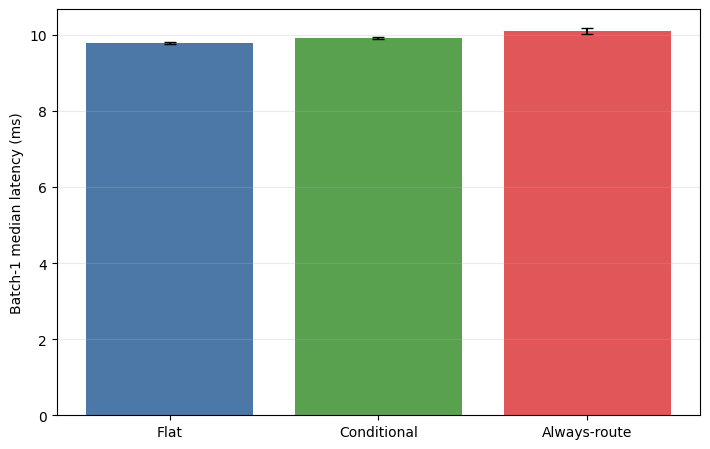

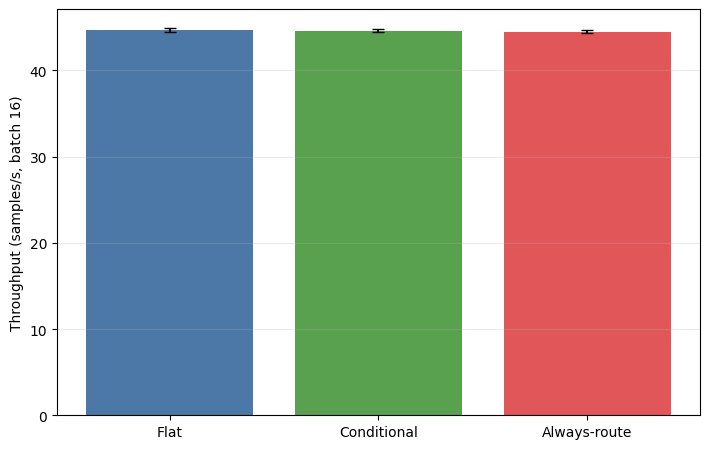

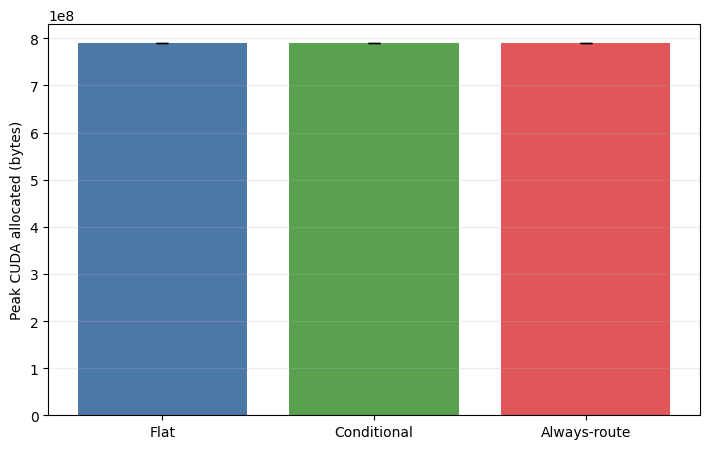

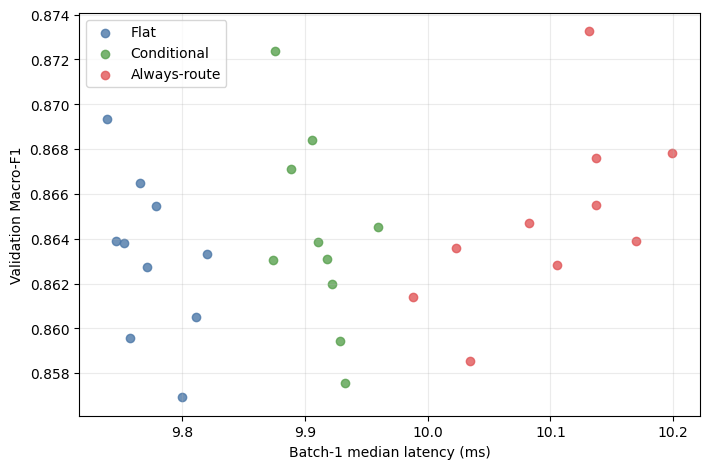

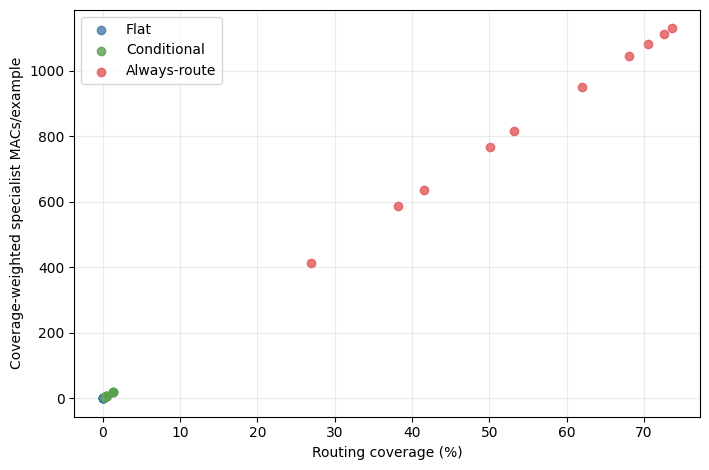

PASS: reviewer-facing PNG and SVG figures saved


In [15]:
SYSTEM_LABELS = {
    "A0_flat": "Flat",
    "A1_conditional": "Conditional",
    "A2_always_route": "Always-route",
}
COLORS = {
    "A0_flat": "#4C78A8",
    "A1_conditional": "#59A14F",
    "A2_always_route": "#E15759",
}
EXPECTED_FIGURE_FILES = [
    "phase12_batch1_latency_by_system.png",
    "phase12_batch1_latency_by_system.svg",
    "phase12_throughput_by_system.png",
    "phase12_throughput_by_system.svg",
    "phase12_peak_vram_by_system.png",
    "phase12_peak_vram_by_system.svg",
    "phase12_macro_f1_vs_latency.png",
    "phase12_macro_f1_vs_latency.svg",
    "phase12_coverage_vs_weighted_macs.png",
    "phase12_coverage_vs_weighted_macs.svg",
]

def save_figure(figure, stem):
    figure.tight_layout()
    for extension in ("png", "svg"):
        figure.savefig(
            FIGURE_DIR / f"{stem}.{extension}",
            dpi=220,
            bbox_inches="tight",
        )
    plt.show()
    plt.close(figure)


def bar_figure(frame, mean_column, sd_column, ylabel, stem):
    selected = frame.set_index("system_id").loc[SYSTEMS]
    figure, axis = plt.subplots(figsize=(7.2, 4.6))
    x = np.arange(len(SYSTEMS))
    axis.bar(
        x,
        selected[mean_column],
        yerr=selected[sd_column].fillna(0),
        capsize=4,
        color=[COLORS[system] for system in SYSTEMS],
    )
    axis.set_xticks(x, [SYSTEM_LABELS[system] for system in SYSTEMS])
    axis.set_ylabel(ylabel)
    axis.grid(axis="y", alpha=0.25)
    save_figure(figure, stem)


bar_figure(
    phase12_batch1_latency_summary,
    "mean_batch1_median_latency_ms",
    "sd_batch1_median_latency_ms",
    "Batch-1 median latency (ms)",
    "phase12_batch1_latency_by_system",
)
bar_figure(
    phase12_throughput_summary,
    "mean_throughput_mean_samples_per_second",
    "sd_throughput_mean_samples_per_second",
    "Throughput (samples/s, batch 16)",
    "phase12_throughput_by_system",
)
bar_figure(
    phase12_vram_summary,
    "mean_peak_cuda_allocated_bytes",
    "sd_peak_cuda_allocated_bytes",
    "Peak CUDA allocated (bytes)",
    "phase12_peak_vram_by_system",
)

figure, axis = plt.subplots(figsize=(7.2, 4.8))
for system_id in SYSTEMS:
    selected = phase12_efficiency_seedwise[
        phase12_efficiency_seedwise["system_id"] == system_id
    ]
    axis.scatter(
        selected["batch1_median_latency_ms"],
        selected["macro_f1"],
        label=SYSTEM_LABELS[system_id],
        color=COLORS[system_id],
        alpha=0.8,
    )
axis.set_xlabel("Batch-1 median latency (ms)")
axis.set_ylabel("Validation Macro-F1")
axis.grid(alpha=0.25)
axis.legend()
save_figure(figure, "phase12_macro_f1_vs_latency")

figure, axis = plt.subplots(figsize=(7.2, 4.8))
for system_id in SYSTEMS:
    selected = phase12_efficiency_seedwise[
        phase12_efficiency_seedwise["system_id"] == system_id
    ]
    axis.scatter(
        100.0 * selected["routing_coverage"],
        selected["coverage_weighted_added_macs_per_example"],
        label=SYSTEM_LABELS[system_id],
        color=COLORS[system_id],
        alpha=0.8,
    )
axis.set_xlabel("Routing coverage (%)")
axis.set_ylabel("Coverage-weighted specialist MACs/example")
axis.grid(alpha=0.25)
axis.legend()
save_figure(figure, "phase12_coverage_vs_weighted_macs")
assert sorted(path.name for path in FIGURE_DIR.iterdir()) == sorted(
    EXPECTED_FIGURE_FILES
)
print("PASS: reviewer-facing PNG and SVG figures saved")


## Export and completion

The final gate writes all tables, freezes the Phase 12 protocol, checks timing and
VRAM structure, verifies that no forbidden split was accessed, builds an exact
SHA-256 manifest, and creates the deterministic result ZIP twice to confirm the
archive hash.


In [16]:
phase12_structure_audit = pd.DataFrame(
    [
        {
            "check": "phase10_reproduction_passes",
            "observed": int(
                phase12_reproduction_seedwise["status"].eq("PASS").sum()
            ),
            "expected": 10,
            "passed": bool(
                phase12_reproduction_seedwise["status"].eq("PASS").all()
            ),
        },
        {
            "check": "selected_phase8_heads",
            "observed": verified_selected_head_count,
            "expected": len(ALL_SEEDS) * K_FIXED,
            "passed": verified_selected_head_count
            == len(ALL_SEEDS) * K_FIXED,
        },
        {
            "check": "batch1_raw_rows",
            "observed": len(phase12_batch1_latency_raw),
            "expected": EXPECTED_BATCH1_RAW_ROWS,
            "passed": len(phase12_batch1_latency_raw)
            == EXPECTED_BATCH1_RAW_ROWS,
        },
        {
            "check": "throughput_raw_rows",
            "observed": len(phase12_throughput_raw),
            "expected": EXPECTED_THROUGHPUT_RAW_ROWS,
            "passed": len(phase12_throughput_raw)
            == EXPECTED_THROUGHPUT_RAW_ROWS,
        },
        {
            "check": "fresh_vram_workers",
            "observed": len(phase12_vram_seedwise),
            "expected": EXPECTED_VRAM_ROWS,
            "passed": len(phase12_vram_seedwise) == EXPECTED_VRAM_ROWS,
        },
        {
            "check": "latency_interleaved_structure",
            "observed": latency_audit["unit_count"],
            "expected": len(ALL_SEEDS)
            * BATCH1_INTERLEAVED_ROUNDS
            * BATCH1_EXAMPLES,
            "passed": latency_audit["passed"],
        },
        {
            "check": "throughput_interleaved_structure",
            "observed": throughput_audit["unit_count"],
            "expected": len(ALL_SEEDS) * THROUGHPUT_REPETITIONS,
            "passed": throughput_audit["passed"],
        },
        {
            "check": "latency_order_balance",
            "observed": len(phase12_batch1_order_balance),
            "expected": len(SYSTEMS) * len(SYSTEMS),
            "passed": latency_order_balance,
        },
        {
            "check": "throughput_order_balance",
            "observed": len(phase12_throughput_order_balance),
            "expected": len(SYSTEMS) * len(SYSTEMS),
            "passed": throughput_order_balance,
        },
        {
            "check": "added_parameter_budget",
            "observed": int(
                phase12_parameter_counts_seedwise.loc[
                    phase12_parameter_counts_seedwise["system_id"]
                    == "A1_conditional",
                    "added_parameters",
                ].iloc[0]
            ),
            "expected": 4614,
            "passed": phase12_parameter_counts_seedwise.loc[
                phase12_parameter_counts_seedwise["system_id"]
                != "A0_flat",
                "added_parameters",
            ].eq(4614).all(),
        },
    ]
)
assert phase12_structure_audit["passed"].all()

phase12_input_inventory = pd.DataFrame(ACCESSED_INPUTS)
forbidden_access = phase12_input_inventory[
    phase12_input_inventory["path"].map(
        lambda value: any(
            marker in Path(value).name.lower()
            for marker in ("_test", "combined", "train_locked")
        )
    )
]
assert forbidden_access.empty

frames_to_save = {
    "phase12_input_inventory.csv": phase12_input_inventory,
    "phase12_gpu_metadata.csv": phase12_gpu_metadata,
    "phase12_reproduction_seedwise.csv": phase12_reproduction_seedwise,
    "phase12_batch1_cohort_no_raw_text.csv": phase12_batch1_cohort,
    "phase12_throughput_cohort_no_raw_text.csv": phase12_throughput_cohort,
    "phase12_performance_activation_seedwise.csv": (
        phase12_performance_activation_seedwise
    ),
    "phase12_performance_activation_summary.csv": (
        phase12_performance_activation_summary
    ),
    "phase12_parameter_counts_seedwise.csv": (
        phase12_parameter_counts_seedwise
    ),
    "phase12_parameter_counts_summary.csv": phase12_parameter_counts_summary,
    "phase12_specialist_compute_seedwise.csv": (
        phase12_specialist_compute_seedwise
    ),
    "phase12_specialist_compute_summary.csv": (
        phase12_specialist_compute_summary
    ),
    "phase12_batch1_latency_raw.csv": phase12_batch1_latency_raw,
    "phase12_batch1_latency_round_summaries.csv": (
        phase12_batch1_latency_round_summaries
    ),
    "phase12_batch1_latency_seedwise.csv": (
        phase12_batch1_latency_seedwise
    ),
    "phase12_batch1_latency_summary.csv": phase12_batch1_latency_summary,
    "phase12_batch1_order_balance.csv": phase12_batch1_order_balance,
    "phase12_throughput_raw.csv": phase12_throughput_raw,
    "phase12_throughput_seedwise.csv": phase12_throughput_seedwise,
    "phase12_throughput_summary.csv": phase12_throughput_summary,
    "phase12_throughput_order_balance.csv": (
        phase12_throughput_order_balance
    ),
    "phase12_vram_seedwise_fresh_process.csv": phase12_vram_seedwise,
    "phase12_vram_summary.csv": phase12_vram_summary,
    "phase12_vram_worker_log.csv": phase12_vram_worker_log,
    "phase12_structure_audit.csv": phase12_structure_audit,
    "phase12_efficiency_consolidated_seedwise.csv": (
        phase12_efficiency_seedwise
    ),
    "phase12_efficiency_consolidated_summary.csv": (
        phase12_efficiency_summary
    ),
    "phase12_claim_guardrails.csv": phase12_claim_guardrails,
}
for filename, frame in frames_to_save.items():
    frame.to_csv(OUTPUT_DIR / filename, index=False, float_format="%.17g")

device_properties = torch.cuda.get_device_properties(0)
environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "torch": torch.__version__,
    "cuda_runtime": torch.version.cuda,
    "transformers": __import__("transformers").__version__,
    "gpu_name": torch.cuda.get_device_name(0),
    "gpu_total_memory_bytes": int(device_properties.total_memory),
    "gpu_compute_capability": list(torch.cuda.get_device_capability(0)),
    "gpu_multiprocessor_count": int(device_properties.multi_processor_count),
    "precision": "float32",
    "automatic_mixed_precision": False,
    "timing_scope": "GPU model-side inference",
    "tokenization_timed": False,
    "host_to_device_transfer_timed": False,
}
write_json(OUTPUT_DIR / "phase12_environment.json", environment)

phase12_protocol = {
    "phase": 12,
    "title": "Ten-Seed Efficiency Benchmarking",
    "model_seeds": ALL_SEEDS,
    "systems": SYSTEMS,
    "labels": LABELS,
    "H": HARD_PAIRS,
    "K": K_FIXED,
    "conditional_tau": PRIMARY_TAU,
    "always_route_tau": ALWAYS_ROUTE_TAU,
    "precision": "float32",
    "automatic_mixed_precision": False,
    "maximum_length": MAX_LENGTH,
    "batch1_examples": BATCH1_EXAMPLES,
    "batch1_warmup_per_system": BATCH1_WARMUP_PER_SYSTEM,
    "batch1_interleaved_rounds": BATCH1_INTERLEAVED_ROUNDS,
    "throughput_batch_size": THROUGHPUT_BATCH_SIZE,
    "throughput_repetitions": THROUGHPUT_REPETITIONS,
    "throughput_warmup_per_system": THROUGHPUT_WARMUP_PER_SYSTEM,
    "bootstrap_reps": BOOTSTRAP_REPS,
    "benchmark_cohort_seed": BENCHMARK_COHORT_SEED,
    "timing_order_seed": TIMING_ORDER_SEED,
    "bootstrap_seed": BOOTSTRAP_SEED,
    "validation_sha256": VALIDATION_SHA256,
    "phase8_zip_sha256": PHASE8_ZIP_SHA256,
    "phase9_zip_sha256": PHASE9_ZIP_SHA256,
    "phase10_zip_sha256": PHASE10_ZIP_SHA256,
    "training_performed": False,
    "threshold_tuning_performed": False,
    "allocation_selection_performed": False,
    "external_data_used": False,
    "test_accessed": False,
}
write_json(OUTPUT_DIR / "phase12_protocol.json", phase12_protocol)
protocol_sha256 = sha256_file(OUTPUT_DIR / "phase12_protocol.json")
(OUTPUT_DIR / "phase12_protocol.sha256").write_text(
    protocol_sha256 + "\n", encoding="utf-8"
)
shutil.copy2(worker_path, OUTPUT_DIR / "phase12_vram_worker.py")

execution_summary = {
    "phase": 12,
    "status": "PASS",
    "seed_count": len(ALL_SEEDS),
    "phase10_reproduction_pass_count": int(
        phase12_reproduction_seedwise["status"].eq("PASS").sum()
    ),
    "verified_phase8_head_count": verified_head_count,
    "verified_selected_phase8_head_count": verified_selected_head_count,
    "batch1_raw_rows": len(phase12_batch1_latency_raw),
    "throughput_raw_rows": len(phase12_throughput_raw),
    "vram_worker_pass_count": int(
        phase12_vram_worker_log["returncode"].eq(0).sum()
    ),
    "frozen_K": K_FIXED,
    "frozen_H": HARD_PAIRS,
    "frozen_tau": PRIMARY_TAU,
    "gpu_name": torch.cuda.get_device_name(0),
    "test_accessed": False,
}
write_json(
    OUTPUT_DIR / "phase12_execution_summary.json", execution_summary
)

report_lines = [
    "# Phase 12 Ten-Seed Efficiency Benchmarking Report",
    "",
    "Status: PASS",
    "",
    f"GPU: {torch.cuda.get_device_name(0)}",
    f"Frozen H: {HARD_PAIRS}",
    f"Frozen K: {K_FIXED}",
    f"Frozen tau: {PRIMARY_TAU:.2f}",
    "Phase 10 reproductions: 10/10 PASS",
    "Test data accessed: False",
    "",
    "## Consolidated equal-seed summary",
    "",
    "```csv",
    phase12_efficiency_summary.to_csv(index=False).strip(),
    "```",
    "",
    "## Claim guardrails",
    "",
    "```csv",
    phase12_claim_guardrails.to_csv(index=False).strip(),
    "```",
    "",
    "Timings describe this Kaggle GPU, float32 precision, and model-side scope.",
    "They exclude tokenization, disk I/O, transfer, and serving overhead.",
    "A1 can reduce activated specialist compute at low routing coverage even though all three heads remain resident.",
    "Intervals quantify repeated benchmark variation on one hardware setting.",
    "These efficiency results do not establish deployment safety or clinical suitability.",
    "Dataset class labels are operational labels, not clinical diagnoses.",
    "Phase 12 cannot change H, K, tau, specialist heads, global checkpoints, or the locked-test plan.",
]
(OUTPUT_DIR / "phase12_report.md").write_text(
    "\n".join(report_lines) + "\n", encoding="utf-8"
)

manifest_rows = []
for result_path in sorted(
    path for path in OUTPUT_DIR.rglob("*") if path.is_file()
):
    manifest_rows.append(
        {
            "path": result_path.relative_to(OUTPUT_DIR).as_posix(),
            "sha256": sha256_file(result_path),
            "bytes": result_path.stat().st_size,
        }
    )
pd.DataFrame(manifest_rows).to_csv(
    OUTPUT_DIR / "sha256_manifest.csv", index=False
)
verify_manifest(OUTPUT_DIR)

result_zip = (
    WORKING_ROOT / "MentalDistress_Phase12_Efficiency_Benchmarking_Results.zip"
)
verification_zip = WORKING_ROOT / "phase12_determinism_check.zip"
zip_sha256 = deterministic_zip(
    OUTPUT_DIR, result_zip, OUTPUT_DIR.name
)
verification_sha256 = deterministic_zip(
    OUTPUT_DIR, verification_zip, OUTPUT_DIR.name
)
assert zip_sha256 == verification_sha256
verification_zip.unlink()

print("=" * 76)
print("PHASE 12 COMPLETE")
print("Frozen K:", K_FIXED)
print("Frozen H:", HARD_PAIRS)
print("Frozen tau:", PRIMARY_TAU)
print("GPU:", torch.cuda.get_device_name(0))
print("Phase 10 reproductions: 10 / 10 PASS")
print("Latency rows:", len(phase12_batch1_latency_raw))
print("Throughput rows:", len(phase12_throughput_raw))
print("VRAM workers: 30 / 30 PASS")
print("Results ZIP:", result_zip)
print("ZIP SHA256:", zip_sha256)
print("Test data accessed: False")
print("=" * 76)


PHASE 12 COMPLETE
Frozen K: 3
Frozen H: ['Frustrated|Others', 'Suicidal|Depressed', 'Depressed|Others']
Frozen tau: 0.1
GPU: Tesla T4
Phase 10 reproductions: 10 / 10 PASS
Latency rows: 230400
Throughput rows: 900
VRAM workers: 30 / 30 PASS
Results ZIP: /kaggle/working/MentalDistress_Phase12_Efficiency_Benchmarking_Results.zip
ZIP SHA256: c0ed1d6af54ae0abf377c818fc44a66ff150eaf4e087dd0511ae527bca24adac
Test data accessed: False
